# Projeto Final — Crédito Rural no Brasil em 2025

**Disciplina:** Técnicas de Programação I — DS-PY-004  
**Ferramentas:** Python, Pandas e NumPy

## Etapa 1 — Conhecendo os dados

### 1.1 — Sobre o que é este trabalho?

O **crédito rural** é o dinheiro que os bancos emprestam para quem trabalha no campo: para plantar, criar animais, comprar máquinas ou guardar a colheita.

Todo empréstimo desse tipo é informado ao **Banco Central**, que guarda tudo em um sistema chamado **SICOR**. Nós pegamos esses dados e fizemos perguntas a eles.

- [Fonte oficial — Banco Central do Brasil](https://www.bcb.gov.br/estabilidadefinanceira/micrrural)
- [De onde baixamos os arquivos — Base dos Dados](https://basedosdados.org/dataset/544c9d22-97b7-479a-8eca-94762840b465)

**Período:** só os empréstimos feitos (emitidos) em **2025**.


### Como ler este trabalho

O notebook está organizado por etapas. Cada procedimento apresenta uma explicação breve do que será executado e sua finalidade, seguido pelo código Python e pela interpretação dos resultados.


**Nota sobre resultados:** as interpretações foram revisadas com base nas saídas salvas; a exportação Parquet permanece pendente por ausência de `pyarrow`. O notebook preserva os códigos e as saídas da versão original; os números não foram recalculados nesta revisão textual.


### 1.2 — O que queremos descobrir?

Escolhemos estas 5 perguntas **antes** de fazer qualquer conta:

1. **Estados:** quanto dinheiro e quantos empréstimos foram para cada estado?
2. **Tamanho do produtor:** o valor emprestado muda entre pequeno, médio e grande produtor?
3. **Para que serve o dinheiro:** quanto foi para Custeio (despesas da safra), Investimento (máquinas, estruturas) e outras finalidades?
4. **Concentração:** poucos estados e atividades ficam com a maior parte do dinheiro?
5. **Meses:** o valor emprestado muda ao longo do ano na agricultura e na pecuária?



### 1.3 — Quais arquivos usamos?

São três arquivos, como três planilhas:

| Arquivo | Para que serve? |
|---|---|
| `operacao_2025.csv` | A tabela principal: cada linha é uma parcela de empréstimo, com estado, datas e valor. |
| `empreendimento_2025.csv` | Diz para que serviu o dinheiro (finalidade), em qual atividade e qual produto. |
| `dicionario.csv` | Traduz os códigos. Ex.: o código 2222 quer dizer "Pequeno Produtor Rural". |



### 1.4 — Abrir os arquivos

**Procedimento:** Importar as bibliotecas (`pandas`, `numpy`, `matplotlib`) e abrir os 3 arquivos CSV com `pd.read_csv()`. A última linha faz os números aparecerem com 2 casas decimais.

**Objetivo:** Sem abrir os arquivos não dá para fazer nada. É como abrir as planilhas antes de começar a trabalhar.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np


operacao = pd.read_csv("dados/operacao_2025.csv")
dicionario = pd.read_csv("dados/dicionario.csv")
empreendimento = pd.read_csv("dados/empreendimento_2025.csv")

# Mostra os números com 2 casas decimais em todas as tabelas
pd.options.display.float_format = '{:,.2f}'.format

### 1.5 — Qual o tamanho de cada tabela?

**Procedimento:** Usar `.shape`, que devolve dois números: linhas e colunas.

**Objetivo:** Saber o tamanho da base e conferir se ela atende ao pedido do professor (mínimo de 1.000 linhas e 8 colunas).

In [2]:
print(f"A base principal operacao_2025.csv possui {operacao.shape[0]} registros e {operacao.shape[1]} colunas.")
print(f"A base secundária empreendimento_2025.csv possui {empreendimento.shape[0]} registros e {empreendimento.shape[1]} colunas.")
print(f"A base dicionario.csv possui {dicionario.shape[0]} registros e {dicionario.shape[1]} colunas.")

A base principal operacao_2025.csv possui 2442343 registros e 15 colunas.
A base secundária empreendimento_2025.csv possui 1050 registros e 10 colunas.
A base dicionario.csv possui 52 registros e 5 colunas.


**📊 Interpretação:**

- Tabela de operações: **2.442.343 linhas** e **15 colunas**.
- Tabela de empreendimentos: **1.050 linhas** e **10 colunas**.
- Dicionário: **52 linhas** e **5 colunas**.


### 1.6 — Quais são as colunas?

**Procedimento:** Listar os nomes das colunas com `.columns.tolist()`.

**Objetivo:** Precisamos saber quais informações existem antes de escolher o que analisar.

In [3]:
print(f"Os nomes das colunas da base principal operacao_2025.csv são {operacao.columns.tolist()}")
print(f"Os nomes das colunas da base secundária empreendimento_2025.csv são {empreendimento.columns.tolist()}")
print(f"Os nomes das colunas da base dicionario.csv são {dicionario.columns.tolist()}")

Os nomes das colunas da base principal operacao_2025.csv são ['ano_emissao', 'mes_emissao', 'data_emissao', 'data_vencimento', 'sigla_uf', 'id_referencia_bacen', 'numero_ordem', 'id_categoria_emitente', 'id_empreendimento', 'id_fonte_recurso', 'id_instrumento_credito', 'valor_parcela_credito', 'valor_quantidade_itens_financiados', 'valor_recurso_proprio', 'valor_receita_bruta_esperada']
Os nomes das colunas da base secundária empreendimento_2025.csv são ['id_empreendimento', 'data_inicio', 'data_fim', 'finalidade', 'atividade', 'modalidade', 'produto', 'variedade', 'zoneamento', 'unidade_medida']
Os nomes das colunas da base dicionario.csv são ['id_tabela', 'nome_coluna', 'chave', 'cobertura_temporal', 'valor']


**📊 Interpretação:**

Agora sabemos quais informações temos. O significado de cada coluna.


### 1.7 — Colunas da tabela de operações, numeradas

**Procedimento:** Mostrar as colunas uma embaixo da outra, com número, usando `for` e `enumerate()`.

**Objetivo:** Uma lista numerada é mais fácil de ler e de consultar depois.

In [4]:
print("Os nomes das colunas da base principal operacao_2025.csv são:")
for numero, coluna in enumerate(operacao.columns, start=1):
    print(f"{numero}. {coluna}")

Os nomes das colunas da base principal operacao_2025.csv são:
1. ano_emissao
2. mes_emissao
3. data_emissao
4. data_vencimento
5. sigla_uf
6. id_referencia_bacen
7. numero_ordem
8. id_categoria_emitente
9. id_empreendimento
10. id_fonte_recurso
11. id_instrumento_credito
12. valor_parcela_credito
13. valor_quantidade_itens_financiados
14. valor_recurso_proprio
15. valor_receita_bruta_esperada


### 1.8 — Colunas da tabela de empreendimentos, numeradas

**Procedimento:** O mesmo da seção anterior, com `for` e `enumerate()`.

**Objetivo:** É nessa tabela que está para que o dinheiro foi usado (finalidade) e em qual atividade.

In [5]:
print("Os nomes das colunas da base secundária empreendimento_2025.csv são:")
for numero, coluna in enumerate(empreendimento.columns, start=1):
    print(f"{numero}. {coluna}")

Os nomes das colunas da base secundária empreendimento_2025.csv são:
1. id_empreendimento
2. data_inicio
3. data_fim
4. finalidade
5. atividade
6. modalidade
7. produto
8. variedade
9. zoneamento
10. unidade_medida


### 1.9 — Colunas do dicionário, numeradas

**Procedimento:** O mesmo da seção anterior, com `for` e `enumerate()`.

**Objetivo:** O dicionário traduz os códigos; precisamos saber como ele está organizado.

In [6]:
print("Os nomes das colunas da base dicionario.csv são:")
for numero, coluna in enumerate(dicionario.columns, start=1):
    print(f"{numero}. {coluna}")

Os nomes das colunas da base dicionario.csv são:
1. id_tabela
2. nome_coluna
3. chave
4. cobertura_temporal
5. valor


### 1.10 — Exemplo de linhas da tabela de operações

**Procedimento:** Mostrar as 5 primeiras linhas com `.head(5)`.

**Objetivo:** Ver exemplos reais ajuda a entender o formato dos dados. Essas 5 linhas não representam a base inteira.

In [7]:
operacao.head(5)

,ano_emissao,mes_emissao,data_emissao,data_vencimento,sigla_uf,id_referencia_bacen,numero_ordem,id_categoria_emitente,id_empreendimento,id_fonte_recurso,id_instrumento_credito,valor_parcela_credito,valor_quantidade_itens_financiados,valor_recurso_proprio,valor_receita_bruta_esperada
0,2025,11,2025-11-12,2026-11-11,AL,521092090,1,2222,12010040000041,201,1,"30,000.00",NaN,NaN,"126,500.00"
1,2025,4,2025-04-08,2026-11-30,AL,519741649,1,2222,12010040000041,201,10,"93,225.68",NaN,0.00,"408,135.00"
2,2025,3,2025-03-13,2026-11-30,AL,519609806,1,2222,12010040000041,300,10,"86,845.56",NaN,0.00,"394,530.50"
3,2025,4,2025-04-08,2026-11-30,AL,519741594,1,2222,12010040000041,201,10,"33,960.78",NaN,0.00,"145,762.50"
4,2025,2,2025-02-18,2026-12-10,AL,519516592,1,2222,12010040000041,201,10,"31,230.17",NaN,0.00,"141,401.00"


### 1.11 — Exemplo de linhas da tabela de empreendimentos

**Procedimento:** Mostrar as 5 primeiras linhas com `.head(5)`.

**Objetivo:** Ver como aparecem a finalidade, a atividade e o produto.

In [8]:
empreendimento.head(5)

,id_empreendimento,data_inicio,data_fim,finalidade,atividade,modalidade,produto,variedade,zoneamento,unidade_medida
0,23271400000002,1984-01-01,NaN,Investimento,Pecuário(a),AQUISIÇÃO DE ANIMAIS,BÚFALOS (BUBALINOS),NÃO SE APLICA,Não zoneado,Unidade
1,23271300193002,1984-01-01,NaN,Investimento,Pecuário(a),AQUISIÇÃO DE ANIMAIS,BOVINOS,LEITE - MATRIZES (VACAS E CRIAS FÊMEAS PARA P...,Não zoneado,Unidade
2,23276760000002,1984-01-01,NaN,Investimento,Pecuário(a),AQUISIÇÃO DE ANIMAIS,SUÍNOS,NÃO SE APLICA,Não zoneado,Unidade
3,23275580000002,1984-01-01,NaN,Investimento,Pecuário(a),AQUISIÇÃO DE ANIMAIS,OVINOS,NÃO SE APLICA,Não zoneado,Unidade
4,23270820015002,1984-01-01,NaN,Investimento,Pecuário(a),AQUISIÇÃO DE ANIMAIS,APICULTURA,"ABRANGE COMPRA DE ABELHAS, ISOLADAMENTE OU EM ...",Não zoneado,Unidade


### 1.12 — Exemplo de linhas do dicionário

**Procedimento:** Mostrar as 15 primeiras linhas com `.head(15)`.

**Objetivo:** Entender a relação entre código e descrição antes de usar o dicionário.

In [9]:
dicionario.head(15)

,id_tabela,nome_coluna,chave,cobertura_temporal,valor
0,operacao,id_categoria_emitente,2222,2013(1),Pequeno Produtor Rural
1,operacao,id_categoria_emitente,3333,2013(1),Médio Produtor Rural
2,operacao,id_categoria_emitente,4444,2013(1),Grande Produtor Rural
3,operacao,id_categoria_emitente,5555,2012(1)2013,Todas Categorias de Produtores Rurais
4,operacao,id_categoria_emitente,7777,2013(1)2018,Repasse a Cooperativa Singular de Crédito
5,operacao,id_categoria_emitente,8888,2013(1)2018,Repasse a Cooperativa Central de Crédito
6,operacao,id_fonte_recurso,100,2011(1)2099,TESOURO NACIONAL
7,operacao,id_fonte_recurso,201,2011(1)2099,OBRIGATÓRIOS - MCR 6.2
8,operacao,id_fonte_recurso,202,2019(1)2019,EXIGIBILIDADE ADICIONAL DOS RECURSOS À VISTA
9,operacao,id_fonte_recurso,222,2022(1)2023,Exigibilidade Adicional dos Recursos à Vista -...


### 1.13 — Fazer uma cópia de segurança

**Procedimento:** Criar uma cópia da tabela de operações com `.copy()`.

**Objetivo:** É como salvar a planilha com outro nome antes de mexer: o original fica guardado sem mudanças.

In [10]:
operacao_traduzida = operacao.copy()

### 1.14 — Separar os códigos do tipo de produtor

**Procedimento:** Filtrar no dicionário só as linhas da coluna `id_categoria_emitente`.

**Objetivo:** Para depois trocar os códigos (2222, 3333, 4444) por nomes que todo mundo entende.

In [11]:
dicionario_categoria = dicionario[dicionario["nome_coluna"] == "id_categoria_emitente"]
display(dicionario_categoria)

,id_tabela,nome_coluna,chave,cobertura_temporal,valor
0,operacao,id_categoria_emitente,2222,2013(1),Pequeno Produtor Rural
1,operacao,id_categoria_emitente,3333,2013(1),Médio Produtor Rural
2,operacao,id_categoria_emitente,4444,2013(1),Grande Produtor Rural
3,operacao,id_categoria_emitente,5555,2012(1)2013,Todas Categorias de Produtores Rurais
4,operacao,id_categoria_emitente,7777,2013(1)2018,Repasse a Cooperativa Singular de Crédito
5,operacao,id_categoria_emitente,8888,2013(1)2018,Repasse a Cooperativa Central de Crédito


## Etapa 2 — Diagnóstico da qualidade dos dados

Dados reais quase sempre vêm com problemas: células vazias, linhas repetidas, nomes escritos de jeitos diferentes, valores impossíveis.

Nesta etapa vamos **só procurar** esses problemas.

### 2.1 — Tipos de informação e espaço ocupado

**Procedimento:** Usar `.info()` nas três tabelas, que mostra o tipo de cada coluna, quantas células estão preenchidas e a memória usada.

**Objetivo:** Se uma data for lida como texto, o computador não sabe qual mês vem antes de qual. E uma base grande pode deixar o computador lento.

In [12]:
operacao_traduzida.info(show_counts=True, memory_usage="deep")

empreendimento.info(memory_usage="deep")

dicionario.info(memory_usage="deep")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2442343 entries, 0 to 2442342
Data columns (total 15 columns):
 #   Column                              Non-Null Count    Dtype  
---  ------                              --------------    -----  
 0   ano_emissao                         2442343 non-null  int64  
 1   mes_emissao                         2442343 non-null  int64  
 2   data_emissao                        2442343 non-null  object 
 3   data_vencimento                     2442343 non-null  object 
 4   sigla_uf                            2442343 non-null  object 
 5   id_referencia_bacen                 2442343 non-null  int64  
 6   numero_ordem                        2442343 non-null  int64  
 7   id_categoria_emitente               2442343 non-null  int64  
 8   id_empreendimento                   2442343 non-null  int64  
 9   id_fonte_recurso                    2442343 non-null  int64  
 10  id_instrumento_credito              2442343 non-null  int64  
 11  valor_parce

**📊 Interpretação:**

| Tabela | Linhas | Memória | Colunas com vazio |
|---|---:|---:|---|
| Operações | 2.442.343 | 617,2 MB | 3 |
| Empreendimentos | 1.050 | 585,7 KB | 2 |
| Dicionário | 52 | 14,8 KB | nenhuma |

**Problema encontrado:** as **datas foram lidas como texto**.



### 2.2 — Células vazias na tabela de operações

**Procedimento:** Contar os vazios com `isna().sum()` e calcular a porcentagem com `isna().mean() * 100`.

**Objetivo:** Saber o tamanho do problema antes de decidir o que fazer com ele.

In [13]:
faltantes = operacao_traduzida.isna().sum()
percentual = operacao_traduzida.isna().mean() * 100

diagnostico_faltantes = pd.DataFrame({
    "Quantidade de ausentes": faltantes,
    "Percentual (%)": percentual.round(2)
})


display(diagnostico_faltantes)

,Quantidade de ausentes,Percentual (%)
ano_emissao,0,0.00
mes_emissao,0,0.00
data_emissao,0,0.00
data_vencimento,0,0.00
sigla_uf,0,0.00
id_referencia_bacen,0,0.00
numero_ordem,0,0.00
id_categoria_emitente,0,0.00
id_empreendimento,0,0.00
id_fonte_recurso,0,0.00


**📊 Interpretação:**

Três colunas têm muitas células vazias:

| Coluna | Vazias |
|---|---:|
| Valor que o produtor colocou do próprio bolso (`valor_recurso_proprio`) | 70,44% |
| Receita que o produtor espera ter (`valor_receita_bruta_esperada`) | 67,65% |
| Quantidade financiada (`valor_quantidade_itens_financiados`) | 17,93% |


**Cuidado:** célula vazia não é o mesmo que zero. Vazio quer dizer "não informado".

### 2.2.2 — Células vazias na tabela de empreendimentos

**Procedimento:** A mesma contagem com `isna().sum()` e `isna().mean() * 100`.

**Objetivo:** Essa tabela será juntada às operações; precisamos saber se ela está completa.

In [14]:
faltantes_empreendimento = empreendimento.isna().sum()
percentual_empreendimento = empreendimento.isna().mean() * 100

diagnostico_empreendimento = pd.DataFrame({
    "Quantidade de ausentes": faltantes_empreendimento,
    "Percentual (%)": percentual_empreendimento.round(2)
})

display(diagnostico_empreendimento)

,Quantidade de ausentes,Percentual (%)
id_empreendimento,0,0.00
data_inicio,0,0.00
data_fim,1019,97.05
finalidade,0,0.00
atividade,0,0.00
modalidade,0,0.00
produto,0,0.00
variedade,0,0.00
zoneamento,456,43.43
unidade_medida,0,0.00


**📊 Interpretação:**

- `data_fim`: **1.019** de 1.050 vazias (97,05%).
- `zoneamento`: **456** vazias (43,43%).



### 2.2.3 — Células vazias no dicionário

**Procedimento:** A mesma contagem com `isna().sum()` e `isna().mean() * 100`.

**Objetivo:** Se faltar uma descrição no dicionário, algum código ficaria sem tradução.

In [15]:
faltantes_dicionario = dicionario.isna().sum()
percentual_dicionario = dicionario.isna().mean() * 100

diagnostico_dicionario = pd.DataFrame({
    "Quantidade de ausentes": faltantes_dicionario,
    "Percentual (%)": percentual_dicionario.round(2)
})

display(diagnostico_dicionario)

,Quantidade de ausentes,Percentual (%)
id_tabela,0,0.00
nome_coluna,0,0.00
chave,0,0.00
cobertura_temporal,0,0.00
valor,0,0.00


**📊 Interpretação:**

O dicionário está **completo**, sem nenhuma célula vazia.


### 2.3 — Verificação de registros duplicados

**Procedimento:** Procurar linhas inteiras iguais com `duplicated().sum()`.

**Objetivo:** Uma linha repetida faria o mesmo dinheiro ser somado duas vezes.

In [16]:
duplicados_operacao = operacao_traduzida.duplicated().sum()

duplicados_empreendimento = empreendimento.duplicated().sum()

duplicados_dicionario = dicionario.duplicated().sum()

print("Registros duplicados nas operações:", duplicados_operacao)

print("Registros duplicados nos empreendimentos:", duplicados_empreendimento)

print("Registros duplicados no dicionário:", duplicados_dicionario)

Registros duplicados nas operações: 0
Registros duplicados nos empreendimentos: 0
Registros duplicados no dicionário: 0


### 2.3.3 — Verificação de duplicidade da chave composta

**Procedimento:** Utilizar o método `duplicated()` do Pandas com `subset=["id_referencia_bacen", "numero_ordem"]` para identificar combinações repetidas e `sum()` para contabilizá-las.

**Objetivo:** **Verificar a unicidade da chave composta** utilizada para identificar os registros da tabela de operações.



In [17]:
duplicados_chave_operacao = operacao_traduzida.duplicated(
    subset=["id_referencia_bacen", "numero_ordem"]
).sum()

print(
    "Repetições da combinação de identificadores:",
    duplicados_chave_operacao
)

Repetições da combinação de identificadores: 0


**📊 Interpretação:**

O resultado foi `0` duplicidades, indicando que não existem repetições da chave composta na base analisada. Portanto, não é necessário remover registros duplicados por esse critério.

### 2.3.5 — Verificação de duplicidades nas tabelas auxiliares

**Procedimento:** Utilizar `duplicated(subset=...)` do Pandas para verificar a unicidade de `id_empreendimento` na tabela `empreendimento` e da combinação `id_tabela`, `nome_coluna` e `chave` no `dicionario`. Aplicar `sum()` para contabilizar duplicidades.

**Objetivo:** **Detectar duplicações nas chaves de consulta** que poderiam multiplicar registros nas junções realizadas com `merge()`.



In [18]:
duplicados_chave_empreendimento = empreendimento.duplicated(
    subset=["id_empreendimento"]
).sum()


duplicados_chave_dicionario = dicionario.duplicated(
    subset=["id_tabela", "nome_coluna", "chave"]
).sum()

print(
    "Identificadores repetidos em empreendimentos:",
    duplicados_chave_empreendimento
)

print(
    "Combinações repetidas no dicionário:",
    duplicados_chave_dicionario
)

Identificadores repetidos em empreendimentos: 0
Combinações repetidas no dicionário: 0


**📊 Interpretação:**

Não foram identificadas duplicidades nas chaves analisadas.

### 2.4 — Análise das categorias de finalidade

**Procedimento:** Utilizar o método `value_counts(dropna=False)` do Pandas para contabilizar as ocorrências das categorias da coluna `finalidade`, incluindo possíveis valores ausentes.

**Objetivo:** **Identificar categorias e possíveis inconsistências** de preenchimento e padronização na classificação das finalidades.



In [19]:
contagem_finalidade = empreendimento["finalidade"].value_counts(
    dropna=False
)

print(contagem_finalidade)

finalidade
Custeio             492
Investimento        331
Comercialização     168
Industrialização     59
Name: count, dtype: int64


**📊 Interpretação:**

Existem 4 finalidades:

- Custeio (despesas da safra): 492 tipos de empreendimento.
- Investimento (máquinas, estruturas, animais): 331.
- Comercialização (vender ou guardar a produção): 168.
- Industrialização (beneficiar a produção): 59.


### 2.4.3 — Verificação da padronização das categorias

**Procedimento:** Utilizar `.str.strip()` para remover espaços nas extremidades dos textos, `.str.casefold()` para normalizar diferenças de maiúsculas e minúsculas, `sum()` para contar registros alterados por espaços extras e `nunique()` para contabilizar categorias distintas.

**Objetivo:** **Verificar a padronização da coluna `finalidade`** e identificar alterações de formatação que possam distorcer agrupamentos.



In [20]:
original = empreendimento["finalidade"]

padronizada = original.str.strip().str.casefold()

inconsistentes = (
    original.str.casefold() != padronizada
).sum()

print("Registros com espaços extras:", inconsistentes)

print(
    "Quantidade de categorias após padronização:",
    padronizada.nunique()
)

Registros com espaços extras: 0
Quantidade de categorias após padronização: 4


**📊 Interpretação:**

Nenhum espaço sobrando, e continuam 4 finalidades. **A coluna está correta.**

### 2.4.5 — Verificação das demais colunas categóricas

**Procedimento:** Utilizar um laço `for` para avaliar as colunas `atividade`, `modalidade` e `produto`. Aplicar `.str.strip()`, `.str.casefold()`, `nunique()`, `sum()` e `value_counts(dropna=False).head(10)` para examinar padronização e frequência das categorias.

**Objetivo:** **Identificar inconsistências nas colunas categóricas** utilizadas nos agrupamentos posteriores.



In [21]:
colunas = ["atividade", "modalidade", "produto"]

for coluna in colunas:

    original = empreendimento[coluna]
    padronizada = original.str.strip().str.casefold()

    print(f"\nColuna: {coluna}")

    print("Categorias originais:", original.nunique())

    print("Categorias padronizadas:", padronizada.nunique())

    print(
        "Registros com espaços extras:",
        (original.str.casefold() != padronizada).sum()
    )

    print("\nCategorias mais frequentes:")
    print(original.value_counts(dropna=False).head(10))


Coluna: atividade
Categorias originais: 2
Categorias padronizadas: 2
Registros com espaços extras: 0

Categorias mais frequentes:
atividade
Agrícola       842
Pecuário(a)    208
Name: count, dtype: int64

Coluna: modalidade
Categorias originais: 41
Categorias padronizadas: 41
Registros com espaços extras: 0

Categorias mais frequentes:
modalidade
LAVOURA                                               417
FORMAÇÃO DE CULTURAS PERENES                           97
MÁQUINAS, EQUIPAMENTOS, MATERIAIS E UTENSÍLIOS         79
ESTOCAGEM                                              63
BENEFICIAMENTO OU INDUSTRIALIZAÇÃO                     55
FGPP-Financiamento para Garantia de Preços ao Prod     47
SERVIÇOS PROFISSIONAIS/TÉCNICOS                        38
FEE (EX-LEC)                                           30
AQUISIÇÃO DE ATIVOS OPERACIONAIS                       23
AQUISIÇÃO DE ANIMAIS                                   21
Name: count, dtype: int64

Coluna: produto
Categorias originais: 316
C

**📊 Interpretação:**

- Atividade: 2 tipos (**Agrícola** e **Pecuário(a)**).
- Modalidade: 41 tipos.
- Produto: 316 tipos.


### 2.4.7 — Verificação de valores numéricos inválidos e ausentes

**Procedimento:** Utilizar um laço `for`, as comparações `< 0` e `== 0` e os métodos `isna()` e `sum()` do Pandas para contar valores negativos, iguais a zero e ausentes nas três colunas numéricas.

**Objetivo:** **Identificar valores potencialmente inválidos ou incompletos**, distinguindo zeros que podem ser legítimos de possíveis erros de dados.



In [22]:
colunas_valores = [
    "valor_parcela_credito",
    "valor_recurso_proprio",
    "valor_receita_bruta_esperada"
]


for coluna in colunas_valores:

    print(f"\nColuna: {coluna}")

    print("Valores negativos:", (operacao_traduzida[coluna] < 0).sum())

    print("Valores iguais a zero:", (operacao_traduzida[coluna] == 0).sum())

    print("Valores ausentes:", operacao_traduzida[coluna].isna().sum())


Coluna: valor_parcela_credito
Valores negativos: 0
Valores iguais a zero: 0
Valores ausentes: 0

Coluna: valor_recurso_proprio
Valores negativos: 0
Valores iguais a zero: 541844
Valores ausentes: 1720391

Coluna: valor_receita_bruta_esperada
Valores negativos: 0
Valores iguais a zero: 0
Valores ausentes: 1652191


**📊 Interpretação:**

| Coluna | Negativos | Zerados | Vazios |
|---|---:|---:|---:|
| Valor da parcela | 0 | 0 | 0 |
| Valor do próprio bolso | 0 | 541.844 | 1.720.391 |
| Receita esperada | 0 | 0 | 1.652.191 |

- **Nenhum valor negativo.**
- O **valor da parcela** está perfeito: sem negativos, sem zeros, sem vazios.
- No "valor do próprio bolso", **zero e vazio são coisas diferentes**: zero quer dizer "o produtor não colocou dinheiro"; vazio quer dizer "não foi informado".

### 2.4.9 — Integração das tabelas de dados

**Procedimento:** Utilizar `pd.merge()` com `how="left"` para integrar `operacao_traduzida`, `empreendimento` e o subconjunto do `dicionario` relativo a `id_fonte_recurso`. Utilizar `drop(columns=...)` para remover cinco colunas não previstas para as análises.

**Objetivo:** **Consolidar os dados das operações**, incorporando informações dos empreendimentos e descrições das fontes de recursos sem alterar as tabelas originais.



In [23]:
df_resultado = pd.merge(
    operacao_traduzida,
    empreendimento,
    on='id_empreendimento',
    how='left'
)


dic_fonte = dicionario[dicionario['nome_coluna'] == 'id_fonte_recurso']
df_resultado = pd.merge(
    df_resultado,
    dic_fonte[['chave', 'valor']],
    left_on='id_fonte_recurso',
    right_on='chave',
    how='left'
)

df_resultado = df_resultado.drop(columns=['chave', 'data_fim', 'valor_receita_bruta_esperada', 'valor_recurso_proprio', 'valor_quantidade_itens_financiados'])

display(df_resultado.head(5))

,ano_emissao,mes_emissao,data_emissao,data_vencimento,sigla_uf,id_referencia_bacen,numero_ordem,id_categoria_emitente,id_empreendimento,id_fonte_recurso,...,valor_parcela_credito,data_inicio,finalidade,atividade,modalidade,produto,variedade,zoneamento,unidade_medida,valor
0,2025,11,2025-11-12,2026-11-11,AL,521092090,1,2222,12010040000041,201,...,"30,000.00",2009-09-21,Custeio,Agrícola,LAVOURA,ABACAXI,NÃO SE APLICA,Zoneado,Hectare,OBRIGATÓRIOS - MCR 6.2
1,2025,4,2025-04-08,2026-11-30,AL,519741649,1,2222,12010040000041,201,...,"93,225.68",2009-09-21,Custeio,Agrícola,LAVOURA,ABACAXI,NÃO SE APLICA,Zoneado,Hectare,OBRIGATÓRIOS - MCR 6.2
2,2025,3,2025-03-13,2026-11-30,AL,519609806,1,2222,12010040000041,300,...,"86,845.56",2009-09-21,Custeio,Agrícola,LAVOURA,ABACAXI,NÃO SE APLICA,Zoneado,Hectare,POUPANÇA RURAL - CONTROLADOS - SUBVENÇÃO ECONÔ...
3,2025,4,2025-04-08,2026-11-30,AL,519741594,1,2222,12010040000041,201,...,"33,960.78",2009-09-21,Custeio,Agrícola,LAVOURA,ABACAXI,NÃO SE APLICA,Zoneado,Hectare,OBRIGATÓRIOS - MCR 6.2
4,2025,2,2025-02-18,2026-12-10,AL,519516592,1,2222,12010040000041,201,...,"31,230.17",2009-09-21,Custeio,Agrícola,LAVOURA,ABACAXI,NÃO SE APLICA,Zoneado,Hectare,OBRIGATÓRIOS - MCR 6.2


**📊 Interpretação:**

As duas junções foram executadas utilizando o método `pd.merge()`, resultando no DataFrame `df_resultado`, com **21 colunas**.

Foram removidas **5 colunas** consideradas desnecessárias para as análises previstas, mantendo os arquivos originais inalterados.

**Atenção:** A integridade dos dados após as junções ainda precisa ser validada, verificando possíveis **duplicidades, perdas de registros e valores ausentes**.


### 2.4.10 — Verificação da consistência das datas

**Procedimento:** Utilizar a função `pd.to_datetime()` do Pandas, com o parâmetro `errors="coerce"`, para **converter e validar as datas** de emissão e vencimento. Aplicar `isna().sum()` para contabilizar datas inválidas ou ausentes, `dt.year` para identificar emissões fora de **2025** e o operador `<` para verificar vencimentos anteriores à emissão.

**Objetivo:** Avaliar a **qualidade e a consistência temporal dos registros**, identificando datas inválidas, emissões fora do período analisado e vencimentos anteriores à contratação, que poderiam comprometer a confiabilidade das análises.


In [24]:
emissao = pd.to_datetime(
    operacao_traduzida["data_emissao"],
    errors="coerce"
)

vencimento = pd.to_datetime(
    operacao_traduzida["data_vencimento"],
    errors="coerce"
)


print("Datas de emissão inválidas:", emissao.isna().sum())

print("Datas de vencimento inválidas:", vencimento.isna().sum())

# Verificar emissões fora de 2025
fora_2025 = (emissao.dt.year != 2025).sum()

print("Emissões fora de 2025:", fora_2025)

# Verificar vencimentos anteriores à emissão
vencimento_errado = (vencimento < emissao).sum()

print("Vencimentos anteriores à emissão:", vencimento_errado)

Datas de emissão inválidas: 0
Datas de vencimento inválidas: 0
Emissões fora de 2025: 0
Vencimentos anteriores à emissão: 0


**📊 Interpretação:**

A verificação apresentou os seguintes resultados:

- **Datas de emissão inválidas ou ausentes:** 0 registros.
- **Datas de vencimento inválidas ou ausentes:** 0 registros.
- **Emissões fora de 2025:** 0 registros.
- **Vencimentos anteriores à emissão:** 0 registros.

Os resultados indicam que **não foram identificadas inconsistências nas datas**, considerando os critérios avaliados.

Todas as datas de emissão pertencem ao ano de **2025**, e nenhum vencimento registrado ocorre antes da respectiva emissão.


### 2.5 — Conversão das colunas de datas para `datetime`

**Procedimento:** Utilizar a função `pd.to_datetime()` do Pandas, com o parâmetro `errors="coerce"`, para **converter as colunas de datas** `data_emissao`, `data_vencimento`, `data_inicio` e `data_fim` para o tipo `datetime`. Valores que não puderem ser convertidos serão representados por `NaT` (Not a Time).

**Objetivo:** **Padronizar os tipos de dados das colunas temporais**, permitindo realizar cálculos de prazos, comparações entre datas e agrupamentos por períodos, como meses e anos, nas etapas posteriores da análise.


In [25]:

operacao_traduzida["data_emissao"] = pd.to_datetime(
    operacao_traduzida["data_emissao"],
    errors="coerce"
)

operacao_traduzida["data_vencimento"] = pd.to_datetime(
    operacao_traduzida["data_vencimento"],
    errors="coerce"
)


empreendimento["data_inicio"] = pd.to_datetime(
    empreendimento["data_inicio"],
    errors="coerce"
)

empreendimento["data_fim"] = pd.to_datetime(
    empreendimento["data_fim"],
    errors="coerce"
)

**📊 Interpretação:**

A conversão das quatro colunas foi executada utilizando `pd.to_datetime()`, sem apresentar erros de execução.

As colunas `data_emissao` e `data_vencimento` pertencem à tabela `operacao_traduzida`, enquanto `data_inicio` e `data_fim` pertencem à tabela `empreendimento`.

**Atenção:** A execução sem erros não garante que todas as datas foram convertidas em valores válidos. Como foi utilizado `errors="coerce"`, valores inválidos são transformados em `NaT`.



### 2.5.1 — Validação dos tipos de dados após a conversão

**Procedimento:** Utilizar o atributo `.dtype` do Pandas para **verificar o tipo de dado** das colunas `data_emissao`, `data_vencimento`, `data_inicio` e `data_fim`, após a aplicação de `pd.to_datetime()`.

**Objetivo:** **Confirmar a conversão das colunas para o tipo `datetime`**, garantindo que os dados estejam estruturados adequadamente para realizar operações temporais, como cálculos de prazos e agrupamentos por períodos.


In [26]:
# Verificar os tipos das colunas de datas
print(operacao_traduzida["data_emissao"].dtype)
print(operacao_traduzida["data_vencimento"].dtype)

print(empreendimento["data_inicio"].dtype)
print(empreendimento["data_fim"].dtype)

datetime64[ns]
datetime64[ns]
datetime64[ns]
datetime64[ns]


**📊 Interpretação:**

As quatro colunas apresentaram o tipo **`datetime64[ns]`**, confirmando que a conversão dos tipos de dados foi realizada.

- **`data_emissao`:** `datetime64[ns]`
- **`data_vencimento`:** `datetime64[ns]`
- **`data_inicio`:** `datetime64[ns]`
- **`data_fim`:** `datetime64[ns]`

**Conclusão:** As quatro colunas estão no formato adequado para realizar operações com datas no Pandas.

## 2.6 — Validação da integridade após a integração das tabelas

Após a integração das tabelas por meio de `pd.merge()`, é necessário verificar se os registros da base principal foram preservados e se as informações das tabelas auxiliares foram incorporadas corretamente.

As principais verificações incluem a **quantidade de registros antes e depois da integração**, possíveis **duplicidades** e a presença de **valores ausentes** nas informações incorporadas.

### 2.6.1 — Verificação da quantidade de registros e correspondência dos empreendimentos

**Procedimento:** Utilizar `len()` para comparar o total de linhas de `operacao_traduzida` e `df_resultado`, `if/else` para avaliar a igualdade e `isna().sum()` para contar registros sem `finalidade`.

**Objetivo:** **Verificar a preservação da contagem de linhas e o preenchimento da finalidade** após as integrações, sem presumir que essas verificações garantam a integridade de todas as chaves.



In [27]:
linhas_antes = len(operacao_traduzida)
linhas_depois = len(df_resultado)

print("Linhas antes do merge:", linhas_antes)
print("Linhas depois do merge:", linhas_depois)

if linhas_antes == linhas_depois:
    print("OK: o número de linhas não mudou.")
else:
    print("ATENÇÃO: o número de linhas mudou!")

sem_empreendimento = df_resultado["finalidade"].isna().sum()
print("Operações sem empreendimento encontrado:", sem_empreendimento)

Linhas antes do merge: 2442343
Linhas depois do merge: 2442343
OK: o número de linhas não mudou.
Operações sem empreendimento encontrado: 0


**📊 Interpretação:**

A comparação apresentou os seguintes resultados:

- **Registros antes da integração:** 2.442.343.
- **Registros após a integração:** 2.442.343.
- **Diferença na quantidade de registros:** 0.
- **Operações sem finalidade identificada:** 0.

Os resultados demonstram que a **quantidade total de registros foi preservada** e que todas as operações possuem informação na coluna `finalidade` após a integração.

**Conclusão:** Não foram identificadas alterações na quantidade total de registros nem valores ausentes na coluna `finalidade`. A verificação da chave composta e das demais informações incorporadas será necessária para complementar a validação da integridade.

### 2.6.2 — Padronização e validação da fonte de recursos

**Procedimento:** Utilizar `rename(columns={"valor": "fonte_recurso"})` para tornar o nome da coluna mais claro, `isna().sum()` para contabilizar descrições ausentes e `len()` para contar os registros.

**Objetivo:** **Padronizar a identificação da fonte de recursos** e verificar o preenchimento da descrição após a integração.



In [28]:
df_resultado = df_resultado.rename(columns={"valor": "fonte_recurso"})

sem_fonte = df_resultado["fonte_recurso"].isna().sum()
print("Linhas sem descrição da fonte de recurso:", sem_fonte)

print("Linhas na tabela:", len(df_resultado))

Linhas sem descrição da fonte de recurso: 0
Linhas na tabela: 2442343


**📊 Interpretação:**

A verificação apresentou os seguintes resultados:

- **Registros sem descrição da fonte de recursos:** 0.
- **Total de registros no DataFrame:** 2.442.343.

O método `rename()` alterou o nome da coluna `valor` para `fonte_recurso`, tornando sua finalidade mais clara.

O resultado de **0 valores ausentes** indica que todas as operações possuem uma informação preenchida na coluna `fonte_recurso`.

A quantidade total permaneceu em **2.442.343 registros**, igual à apresentada na verificação anterior.

**Conclusão:** Não foram identificados valores ausentes na coluna `fonte_recurso`, e a quantidade total de registros permaneceu inalterada nesta etapa.

### 2.6.3 — Integração e validação das categorias de produtores

**Procedimento:** Filtrar o `dicionario` por `nome_coluna == "id_categoria_emitente"`, utilizar `rename(columns=...)` para organizar a tabela auxiliar e aplicar `merge(how="left")` na chave `id_categoria_emitente`. Conferir a quantidade de linhas com `len()` e as categorias com `value_counts(dropna=False)`.

**Objetivo:** **Incorporar a classificação dos produtores rurais** e verificar se a integração preserva o total de registros e apresenta categorias não preenchidas.



In [29]:
# Tabela auxiliar só com o código e o nome da categoria
categorias = dicionario[dicionario["nome_coluna"] == "id_categoria_emitente"]
categorias = categorias[["chave", "valor"]]
categorias = categorias.rename(columns={"chave": "id_categoria_emitente", "valor": "tipo_de_produtor"})

linhas_antes = len(df_resultado)

base = df_resultado.merge(categorias, on="id_categoria_emitente", how="left")

linhas_depois = len(base)

print("Linhas antes do merge:", linhas_antes)
print("Linhas depois do merge:", linhas_depois)

if linhas_antes == linhas_depois:
    print("OK: o número de linhas não mudou.")
else:
    print("ATENÇÃO: o número de linhas mudou!")

print()
print("Quantidade de linhas por categoria:")
print(base["tipo_de_produtor"].value_counts(dropna=False))

Linhas antes do merge: 2442343
Linhas depois do merge: 2442343
OK: o número de linhas não mudou.

Quantidade de linhas por categoria:
tipo_de_produtor
Pequeno Produtor Rural    2070735
Médio Produtor Rural       263257
Grande Produtor Rural      108351
Name: count, dtype: int64


**📊 Interpretação:**

A integração apresentou os seguintes resultados:

- **Registros antes da junção:** 2.442.343.
- **Registros após a junção:** 2.442.343.
- **Diferença na quantidade de registros:** 0.

A distribuição das operações por categoria foi:

- **Pequeno Produtor Rural:** 2.070.735 operações.
- **Médio Produtor Rural:** 263.257 operações.
- **Grande Produtor Rural:** 108.351 operações.

Não foram identificados valores ausentes na classificação `tipo_de_produtor`.

**Conclusão:** A junção preservou a **quantidade total de registros** e permitiu classificar todas as operações em três categorias de produtores rurais.

O DataFrame `base` passa a reunir as informações necessárias para realizar **análises comparativas por tipo de produtor**, incluindo quantidade de operações, valores contratados e distribuição dos recursos.

## 2.7 — Identificação e avaliação de valores atípicos (outliers)

**O que é um valor fora do padrão?** É um valor muito diferente dos outros **do mesmo grupo**.

**Exemplo do dia a dia:** um empréstimo de R$ 2 milhões é **estranho** para um pequeno produtor, mas pode ser **normal** para um grande produtor. Por isso, **comparamos cada produtor com os do mesmo tamanho**, nunca com todos misturados.

### Como decidimos o que é "fora do padrão" (método IQR)

Imagine as parcelas de um grupo colocadas em fila, da menor para a maior, e divididas em 4 partes iguais:

1. **Q1** é o valor que fica a 1/4 da fila.
2. **Q3** é o valor que fica a 3/4 da fila.
3. A **faixa normal** do meio vai de Q1 até Q3. O tamanho dela se chama **IQR** (Q3 − Q1).
4. Damos uma "folga" de 1,5 vez essa faixa para cima e para baixo.
5. O que passar dessa folga é **fora do padrão**.

**Em fórmula:** limite de cima = Q3 + 1,5 × IQR.

**Por que esse método?** Ele usa a **posição na fila**, e não a média. Assim, um único valor gigante não estraga o cálculo. É um método muito usado e fácil de explicar.

### 2.7.1 — Cálculo dos limites IQR por tipo de produtor

**Procedimento:** Para cada tipo de produtor (com um `for`), calcular Q1, Q3 e a faixa normal (IQR) com `quantile()`, e marcar como `True` na coluna `outlier_iqr` as parcelas que passam do limite.

**Objetivo:** Um empréstimo de R$ 2 milhões é estranho para um pequeno produtor, mas normal para um grande. Por isso cada grupo tem o seu próprio limite.

In [30]:
# Lista com os 3 tipos de produtor
tipos = ["Pequeno Produtor Rural", "Médio Produtor Rural", "Grande Produtor Rural"]

# Começamos dizendo que nenhuma parcela está fora do padrão
base["outlier_iqr"] = False

# Lista onde vamos guardar os limites de cada tipo, para mostrar no final
resultados = []

for tipo in tipos:
    # 1. Pegar só as parcelas deste tipo de produtor
    valores = base[base["tipo_de_produtor"] == tipo]["valor_parcela_credito"]

    # 2. Calcular Q1, Q3 e a faixa normal (IQR)
    q1 = valores.quantile(0.25)
    q3 = valores.quantile(0.75)
    iqr = q3 - q1

    # 3. Calcular os limites
    limite_baixo = q1 - 1.5 * iqr
    limite_cima = q3 + 1.5 * iqr

    # 4. Marcar as parcelas deste tipo que passam dos limites
    eh_deste_tipo = base["tipo_de_produtor"] == tipo
    passou_limite = (base["valor_parcela_credito"] > limite_cima) | (base["valor_parcela_credito"] < limite_baixo)
    base.loc[eh_deste_tipo & passou_limite, "outlier_iqr"] = True

    # 5. Guardar os números para a tabela final
    resultados.append({
        "tipo_de_produtor": tipo,
        "q1": q1,
        "q3": q3,
        "iqr": iqr,
        "limite_baixo": limite_baixo,
        "limite_cima": limite_cima
    })

tabela_limites = pd.DataFrame(resultados)
display(tabela_limites)

print("Total de parcelas marcadas como fora do padrão:", base["outlier_iqr"].sum())

,tipo_de_produtor,q1,q3,iqr,limite_baixo,limite_cima
0,Pequeno Produtor Rural,"4,000.00","35,840.00","31,840.00","-43,760.00","83,600.00"
1,Médio Produtor Rural,"99,097.92","400,000.00","300,902.08","-352,255.20","851,353.12"
2,Grande Produtor Rural,"285,600.00","1,400,000.00","1,114,400.00","-1,386,000.00","3,071,600.00"


Total de parcelas marcadas como fora do padrão: 281892


**📊 Interpretação:**

Pelo método IQR calculado **separadamente para cada tipo de produtor**, os limites superiores foram **R$ 83.600,00** (pequenos), **R$ 851.353,12** (médios) e **R$ 3.071.600,00** (grandes). Foram sinalizados **281.892 registros** como valores atípicos. Todos os limites inferiores calculados foram negativos; isso não significa que haja créditos negativos, apenas que o limite inferior do método ficou abaixo de zero.

### 2.7.2 — Validação da quantidade de registros após a classificação

**Procedimento:** Comparar o número de linhas da `base` com o da tabela original, usando `len()`.

**Objetivo:** Marcar não pode apagar nem duplicar nada. Conferimos para ter certeza.

In [31]:
print("Linhas na tabela original:", len(operacao))
print("Linhas na base:", len(base))

if len(operacao) == len(base):
    print("OK: nenhuma linha foi perdida ou duplicada.")
else:
    print("ATENÇÃO: a quantidade de linhas mudou!")

Linhas na tabela original: 2442343
Linhas na base: 2442343
OK: nenhuma linha foi perdida ou duplicada.


**📊 Interpretação:**

**"OK: nenhuma linha foi perdida ou duplicada"**, a marcação só acrescentou uma coluna, sem mexer nas linhas.

### 2.7.3 — Distribuição dos outliers por categoria de produtor

**Procedimento:** Agrupar por tipo de produtor e calcular de uma vez (com `groupby` + `agg`) o total, a quantidade marcada e a porcentagem.

**Objetivo:** Saber o tamanho do "problema" em cada grupo antes de decidir o que fazer.

In [32]:
resumo_outliers = base.groupby("tipo_de_produtor")["outlier_iqr"].agg(["count", "sum", "mean"])

resumo_outliers.columns = ["total_de_linhas", "quantidade_de_outliers", "percentual_de_outliers"]
resumo_outliers["percentual_de_outliers"] = resumo_outliers["percentual_de_outliers"] * 100

display(resumo_outliers)

,total_de_linhas,quantidade_de_outliers,percentual_de_outliers
tipo_de_produtor,,,
Grande Produtor Rural,108351,8008,7.39
Médio Produtor Rural,263257,21273,8.08
Pequeno Produtor Rural,2070735,252611,12.20


**📊 Interpretação:**

Foram identificados **252.611 registros (12,20%)** de pequenos produtores, **21.273 (8,08%)** de médios e **8.008 (7,39%)** de grandes produtores como outliers pelo IQR de cada grupo. **Proporcionalmente, os pequenos produtores tiveram a maior frequência** de valores sinalizados.

### 2.7.4 — Comparação do IQR geral com o IQR por categoria

**Procedimento:** Repetir a conta do IQR sem separar por grupo e comparar as porcentagens com as da seção anterior.

**Objetivo:** Para provar, com números, que separar por tipo de produtor é o jeito certo.

In [33]:
q1_geral = base["valor_parcela_credito"].quantile(0.25)
q3_geral = base["valor_parcela_credito"].quantile(0.75)
iqr_geral = q3_geral - q1_geral
limite_geral = q3_geral + 1.5 * iqr_geral

print("Limite superior usando a coluna inteira:", round(limite_geral, 2))

base["outlier_geral"] = base["valor_parcela_credito"] > limite_geral

comparacao = base.groupby("tipo_de_produtor")[["outlier_iqr", "outlier_geral"]].mean() * 100
comparacao.columns = ["% outliers por categoria", "% outliers na coluna inteira"]

display(comparacao)

Limite superior usando a coluna inteira: 176250.0


,% outliers por categoria,% outliers na coluna inteira
tipo_de_produtor,,
Grande Produtor Rural,7.39,85.30
Médio Produtor Rural,8.08,55.56
Pequeno Produtor Rural,12.20,3.99


**📊 Interpretação:**

Usando um **único limite superior de R$ 176.250,00** para toda a base, seriam sinalizados **85,30%** dos registros de grandes produtores, **55,56%** dos médios e **3,99%** dos pequenos. Aplicando o IQR por categoria, os percentuais são, respectivamente, **7,39%**, **8,08%** e **12,20%**. A comparação mostra que **o grupo de referência altera fortemente a detecção dos valores atípicos**.

### 2.7.5 — Influência dos outliers sobre a média

**Procedimento:** Calcular a média com `mean()` com e sem os valores marcados e a diferença em %.

**Objetivo:** A média é sensível a valores muito altos. Se 9 pessoas ganham R$ 2 mil e 1 ganha R$ 100 mil, a média dá R$ 11.800, que não representa ninguém.

In [34]:
media_com = base.groupby("tipo_de_produtor")["valor_parcela_credito"].mean()

sem_outliers = base[base["outlier_iqr"] == False]
media_sem = sem_outliers.groupby("tipo_de_produtor")["valor_parcela_credito"].mean()

impacto = pd.DataFrame({
    "media_com_outliers": media_com,
    "media_sem_outliers": media_sem
})

impacto["diferenca_percentual"] = (impacto["media_com_outliers"] / impacto["media_sem_outliers"] - 1) * 100

display(impacto)

,media_com_outliers,media_sem_outliers,diferenca_percentual
tipo_de_produtor,,,
Grande Produtor Rural,"1,758,880.35","820,916.95",114.26
Médio Produtor Rural,"340,396.34","234,077.19",45.42
Pequeno Produtor Rural,"37,612.34","16,025.34",134.71


**📊 Interpretação:**

Ao excluir os registros sinalizados pelo IQR de cada categoria, a média das parcelas passa de **R$ 1.758.880,35 para R$ 820.916,95** (grandes), de **R$ 340.396,34 para R$ 234.077,19** (médios) e de **R$ 37.612,34 para R$ 16.025,34** (pequenos). As médias com outliers são, respectivamente, **114,26%**, **45,42%** e **134,71%** maiores. Isso mostra a influência dos valores extremos sobre a média, sem demonstrar que sejam erros.

### 2.7.6 — Visualização da dispersão dos valores por categoria

**Procedimento:** Fazer um gráfico de caixa (`plt.boxplot`) para cada tipo, em escala logarítmica (a régua cresce de 10 em 10 vezes).

**Objetivo:** Os valores vão de poucos reais a milhões. Numa régua comum, as caixas dos pequenos ficariam esmagadas. **Como ler:** a caixa mostra a metade do meio das parcelas, a linha dentro dela é a mediana e os pontos soltos são os valores fora do padrão.

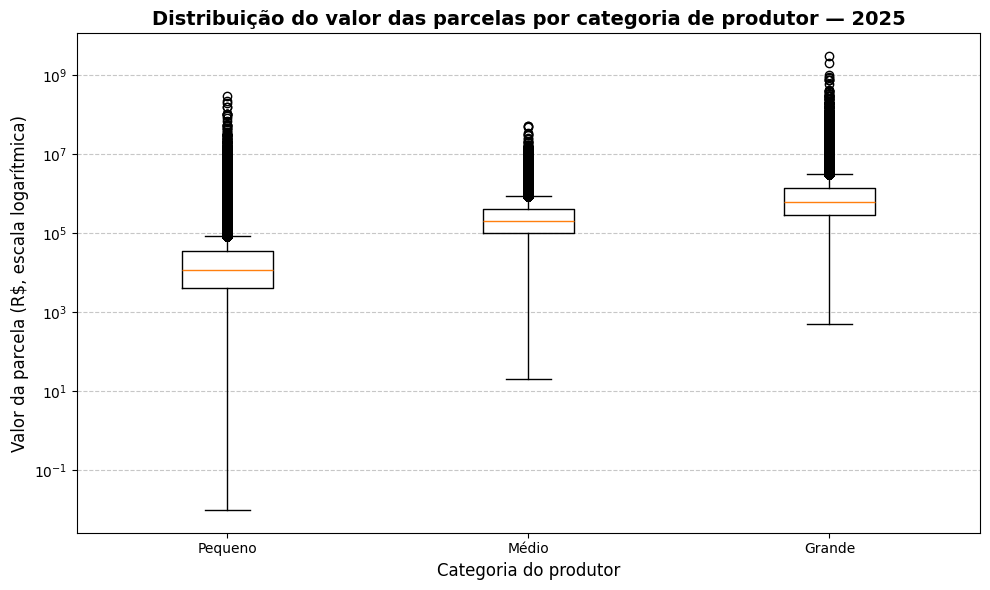

In [35]:
pequeno = base[base["tipo_de_produtor"] == "Pequeno Produtor Rural"]["valor_parcela_credito"]
medio = base[base["tipo_de_produtor"] == "Médio Produtor Rural"]["valor_parcela_credito"]
grande = base[base["tipo_de_produtor"] == "Grande Produtor Rural"]["valor_parcela_credito"]

plt.figure(figsize=(10, 6))

plt.boxplot([pequeno, medio, grande], showfliers=True)

plt.xticks([1, 2, 3], ["Pequeno", "Médio", "Grande"])
plt.yscale("log")

plt.title("Distribuição do valor das parcelas por categoria de produtor — 2025", fontsize=14, fontweight="bold")
plt.xlabel("Categoria do produtor", fontsize=12)
plt.ylabel("Valor da parcela (R$, escala logarítmica)", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

**📊 Interpretação:**

O gráfico de caixas compara as distribuições de `valor_parcela_credito` entre as três categorias. A escala das parcelas difere consideravelmente entre pequenos, médios e grandes produtores, em consonância com os limites e médias apurados nas etapas anteriores. **A identificação de outliers deve considerar a categoria de comparação.**

### 2.7.7 — Decisão de tratamento dos valores atípicos

**Decisão:** **não apagamos nenhum.** Eles ficam na base, com uma marca na coluna `outlier_iqr`.

**Por quê?**

1. Não achamos nenhum sinal de erro de digitação (sem valores negativos, zerados ou datas erradas). Parecem empréstimos **reais**.
2. Apagar esses valores diminuiria o total de dinheiro de cada estado, e as perguntas 1 e 4 dependem desse total.
3. Com a marca, podemos fazer qualquer conta **com e sem** eles e comparar.

**Na prática:** quando falarmos do valor "típico" de um empréstimo, vamos mostrar também a **mediana**.

## Etapa 3 — Limpeza e transformação dos dados

Na Etapa 2 nós **achamos** os problemas. Agora vamos **resolver** cada um e explicar o porquê.

| Problema | Onde achamos | O que fazemos |
|---|---|---|
| Colunas com muitas células vazias | 2.2 | Retiramos (3.1) |
| Zoneamento vazio | 2.2.2 | Escrevemos "Não informado" (3.2) |
| Linhas repetidas | 2.3 | Não havia (3.3) |
| Nome "Pecuário(a)" | 2.4.6 | Trocamos por "Pecuária" (3.4) |
| Datas como texto | 2.1 | Transformamos em data (3.5) |
| Valores fora do padrão | 2.7 | Mantidos e marcados |

### 3.1 — Avaliação e tratamento das colunas com valores ausentes

| Coluna | Vazias | Decisão | Por quê |
|---|---:|---|---|
| Valor do próprio bolso | 70,44% | Retirada | Preencher 70% seria inventar dados. |
| Receita esperada | 67,65% | Retirada | Mesmo motivo, e não serve para as perguntas. |
| Quantidade financiada | 17,93% | Retirada | Não serve para as perguntas e mistura unidades. |
| Data de fim | 97,05% | Retirada | Quase toda vazia e não serve para as perguntas. |
| Zoneamento | 43,43% | **Mantida** | Ver 3.2. |
| **Valor da parcela** | **0%** | **Mantida** | É a coluna principal e está completa. |

**Por que não apagamos as linhas com células vazias?** Porque perderíamos cerca de 70% dos empréstimos, e o valor do empréstimo dessas linhas está certo. Seria jogar fora dado bom.

**A célula abaixo confere** que as colunas foram mesmo retiradas.

### 3.1.1 — Conferir as colunas retiradas

**Procedimento:** Verificar com um `for` se cada coluna ainda está na `base`, e contar os vazios do valor da parcela.

**Objetivo:** Confirmar que a decisão da tabela acima foi aplicada.

In [36]:
colunas_retiradas = [
    "valor_recurso_proprio",
    "valor_receita_bruta_esperada",
    "valor_quantidade_itens_financiados",
    "data_fim"
]

for coluna in colunas_retiradas:
    if coluna in base.columns:
        print(coluna, "-> ainda está na base")
    else:
        print(coluna, "-> retirada")

print()
print("Valores vazios em valor_parcela_credito:", base["valor_parcela_credito"].isna().sum())

valor_recurso_proprio -> retirada
valor_receita_bruta_esperada -> retirada
valor_quantidade_itens_financiados -> retirada
data_fim -> retirada

Valores vazios em valor_parcela_credito: 0


**📊 Interpretação:**

A execução confirmou a retirada de **quatro colunas**: `valor_recurso_proprio`, `valor_receita_bruta_esperada`, `valor_quantidade_itens_financiados` e `data_fim`. A coluna `valor_parcela_credito` apresentou **0 valores ausentes** na verificação executada.

### 3.2 — Tratamento de valores ausentes em zoneamento

**Procedimento:** Escrever "Não informado" nas células vazias com `fillna()`.

**Objetivo:** Assim essas linhas não somem, e quem lê sabe que a informação não foi dada (e não que o empreendimento "não é zoneado").

In [37]:
vazios_antes = base["zoneamento"].isna().sum()

base["zoneamento"] = base["zoneamento"].fillna("Não informado")

vazios_depois = base["zoneamento"].isna().sum()

print("Vazios antes:", vazios_antes)
print("Vazios depois:", vazios_depois)
print()
print(base["zoneamento"].value_counts())

Vazios antes: 1344324
Vazios depois: 0

zoneamento
Não informado    1344324
Não zoneado       720594
Zoneado           377425
Name: count, dtype: int64


**📊 Interpretação:**

A coluna `zoneamento` possuía **1.344.324 valores ausentes**. Após `fillna("Não informado")`, passou a apresentar **0 valores nulos**. A distribuição ficou em **1.344.324** registros “Não informado”, **720.594** “Não zoneado” e **377.425** “Zoneado”. A substituição preserva a ausência de informação como uma categoria explícita; **não significa que o zoneamento real tenha sido descoberto**.

### 3.3 — Verificação da chave composta após as junções

**Procedimento:** Utilizar `duplicated(subset=["id_referencia_bacen", "numero_ordem"]).sum()` na `base` para contabilizar repetições da **chave composta** após as operações de integração.

**Objetivo:** **Confirmar a unicidade da combinação de identificadores** após os `merge()`, complementando a verificação da quantidade de linhas.



In [38]:
duplicados_base = base.duplicated(subset=["id_referencia_bacen", "numero_ordem"]).sum()

print("Linhas repetidas na base:", duplicados_base)

Linhas repetidas na base: 0


**📊 Interpretação:**

A verificação com `duplicated(subset=["id_referencia_bacen", "numero_ordem"])` encontrou **0 repetições da chave composta** na base resultante. Isso confirma a unicidade dessa combinação nos registros analisados, mas não valida por si só a correção de todos os valores.

### 3.4 — Padronização da categoria de atividade

**Procedimento:** Usar uma lista de troca "de → para" com `map()`, como o Localizar e Substituir do Word.

**Objetivo:** "Pecuária" é mais fácil de ler nos gráficos e nas conclusões.

In [39]:
troca_atividade = {
    "Agrícola": "Agrícola",
    "Pecuário(a)": "Pecuária"
}

base["atividade"] = base["atividade"].map(troca_atividade)

print(base["atividade"].value_counts(dropna=False))

atividade
Pecuária    1396018
Agrícola    1046325
Name: count, dtype: int64


**📊 Interpretação:**

Após o mapeamento da coluna `atividade`, foram contabilizados **1.396.018 registros de Pecuária** e **1.046.325 de Agrícola**. A saída não mostra registros sem categoria. A contagem se refere a **linhas da base**, não a produtores distintos.

### 3.5 — Padronização dos tipos de dados temporais na base integrada

**Procedimento:** Converter as datas da `base` com `pd.to_datetime()` e conferir o tipo.

**Objetivo:** A `base` foi montada antes da conversão da seção 2.5, então nela as datas ainda estavam como texto.

In [40]:
base["data_emissao"] = pd.to_datetime(base["data_emissao"], errors="coerce")
base["data_vencimento"] = pd.to_datetime(base["data_vencimento"], errors="coerce")

print(base["data_emissao"].dtype)
print(base["data_vencimento"].dtype)
print("Datas inválidas:", base["data_emissao"].isna().sum() + base["data_vencimento"].isna().sum())

datetime64[ns]
datetime64[ns]
Datas inválidas: 0


**📊 Interpretação:**

As colunas `data_emissao` e `data_vencimento` aparecem como **`datetime64[ns]`**. A verificação executada encontrou **0 datas inválidas ou ausentes** nessas duas colunas da base. O resultado não garante, isoladamente, que cada data corresponda ao evento real.

## 3.6 — Criação de colunas derivadas

Vamos criar 5 colunas novas:

| Coluna nova | O que mostra | Exemplo |
|---|---|---|
| `mes_nome` | O nome do mês | 3 → "Mar" |
| `trimestre` | Em qual trimestre do ano | Março → "1º trimestre" |
| `prazo_dias` | Quantos dias entre o empréstimo e o vencimento | 365 |
| `tipo_prazo` | Se o prazo é curto ou longo | "Curto prazo" |
| `faixa_valor` | Em qual faixa de valor a parcela está | "Até 50 mil" |

### 3.6.1 — Identificação do mês de emissão

**Procedimento:** Criar a coluna `mes_nome` com uma lista "1 é Jan, 2 é Fev..." e `map()`.

**Objetivo:** Nos gráficos, "Mar" é mais fácil de ler que "3". Será usada na pergunta 5.

In [41]:
meses = {
    1: "Jan", 2: "Fev", 3: "Mar", 4: "Abr",
    5: "Mai", 6: "Jun", 7: "Jul", 8: "Ago",
    9: "Set", 10: "Out", 11: "Nov", 12: "Dez"
}

base["mes_nome"] = base["mes_emissao"].map(meses)

print(base[["mes_emissao", "mes_nome"]].drop_duplicates().sort_values("mes_emissao"))

    mes_emissao mes_nome
5             1      Jan
4             2      Fev
2             3      Mar
1             4      Abr
12            5      Mai
11            6      Jun
24            7      Jul
16            8      Ago
7             9      Set
19           10      Out
0            11      Nov
9            12      Dez


**📊 Interpretação:**

A tabela mostra cada número de mês ao lado do seu nome. Se algum mês aparecer sem nome, a lista de troca está incompleta.

### 3.6.2 — Classificação do trimestre de emissão

**Procedimento:** Criar uma regra simples (meses 1 a 3 = 1º trimestre, 4 a 6 = 2º...) e aplicá-la em cada linha com `apply()`.

**Objetivo:** Agrupar por trimestre ajuda a ver em que época do ano se pega mais crédito.

In [42]:
def descobrir_trimestre(mes):
    if mes <= 3:
        return "1º trimestre"
    elif mes <= 6:
        return "2º trimestre"
    elif mes <= 9:
        return "3º trimestre"
    else:
        return "4º trimestre"

base["trimestre"] = base["mes_emissao"].apply(descobrir_trimestre)

print(base["trimestre"].value_counts().sort_index())

trimestre
1º trimestre    450186
2º trimestre    628387
3º trimestre    716050
4º trimestre    647720
Name: count, dtype: int64


**📊 Interpretação:**

As quantidades de registros foram: **450.186** no 1º trimestre, **628.387** no 2º, **716.050** no 3º e **647.720** no 4º. O **3º trimestre** apresentou o maior número de registros. Essa contagem não representa o valor financeiro liberado em cada trimestre.

### 3.6.3 — Cálculo e classificação do prazo das operações

**Procedimento:** Calcular `prazo_dias` (vencimento menos emissão) e criar `tipo_prazo` com `np.where()`, que funciona como o SE do Excel: até 365 dias é "Curto prazo", acima disso, "Longo prazo".

**Objetivo:** O prazo ajuda a entender o tipo de crédito: despesas de uma safra costumam ter prazo curto; máquinas e estruturas, prazo longo.

In [43]:
base["prazo_dias"] = (base["data_vencimento"] - base["data_emissao"]).dt.days

base["tipo_prazo"] = np.where(base["prazo_dias"] <= 365, "Curto prazo", "Longo prazo")

print(base["prazo_dias"].describe())
print()
print(base["tipo_prazo"].value_counts())

count   2,442,343.00
mean        1,140.81
std           943.42
min             3.00
25%           365.00
50%         1,095.00
75%         1,096.00
max         9,131.00
Name: prazo_dias, dtype: float64

tipo_prazo
Longo prazo    1823414
Curto prazo     618929
Name: count, dtype: int64


**📊 Interpretação:**

O prazo médio foi de **1.140,81 dias** e a mediana de **1.095 dias**. Foram classificados **618.929 registros como curto prazo** (até 365 dias) e **1.823.414 como longo prazo** (acima de 365 dias). Esses prazos derivam da diferença entre `data_vencimento` e `data_emissao` e da regra utilizada no código.

### 3.6.4 — Classificação por faixa de valor

**Procedimento:** Separar as parcelas em 4 faixas com `pd.cut()`: até R$ 50 mil, de 50 mil a 200 mil, de 200 mil a 1 milhão e acima de 1 milhão.

**Objetivo:** Faixas com valores redondos são mais fáceis de entender do que milhões de valores diferentes.

In [44]:
limites_faixa = [0, 50000, 200000, 1000000, float("inf")]
nomes_faixa = ["Até 50 mil", "50 mil a 200 mil", "200 mil a 1 milhão", "Acima de 1 milhão"]

base["faixa_valor"] = pd.cut(base["valor_parcela_credito"], bins=limites_faixa, labels=nomes_faixa)

print(base["faixa_valor"].value_counts().sort_index())
print()
print("Linhas sem faixa:", base["faixa_valor"].isna().sum())

faixa_valor
Até 50 mil            1694751
50 mil a 200 mil       469048
200 mil a 1 milhão     224807
Acima de 1 milhão       53737
Name: count, dtype: int64

Linhas sem faixa: 0


**📊 Interpretação:**

A classificação por valor resultou em **1.694.751 parcelas até R$ 50 mil**, **469.048 entre R$ 50 mil e R$ 200 mil**, **224.807 entre R$ 200 mil e R$ 1 milhão** e **53.737 acima de R$ 1 milhão**. Foram identificadas **0 linhas sem faixa** segundo os limites utilizados.

### 3.7 — Exportação da base tratada

**Procedimento:** Salvar a `base` em formato Parquet com `to_parquet()` e comparar o tamanho com o CSV original.

**Objetivo:** O Parquet é compactado (como um ZIP), abre mais rápido e guarda o tipo de cada coluna: data continua sendo data.

In [45]:
import os

try:
    base.to_parquet("dados/base_tratada.parquet", index=False)

    tamanho_csv = os.path.getsize("dados/operacao_2025.csv") / 1024 / 1024
    tamanho_parquet = os.path.getsize("dados/base_tratada.parquet") / 1024 / 1024

    print(f"CSV original: {tamanho_csv:.1f} MB")
    print(f"Parquet tratado: {tamanho_parquet:.1f} MB")

    teste = pd.read_parquet("dados/base_tratada.parquet")
    print("Tipo de data_emissao ao ler o Parquet:", teste["data_emissao"].dtype)
    print("Linhas no Parquet:", len(teste))

except ImportError:
    print("A biblioteca pyarrow não está instalada. O arquivo Parquet não foi gravado.")

A biblioteca pyarrow não está instalada. O arquivo Parquet não foi gravado.


**📊 Interpretação:**

**A exportação para Parquet não foi concluída.** A execução registrou que a biblioteca `pyarrow` **não estava instalada**. Portanto, o notebook não fornece tamanho do arquivo Parquet nem resultado de sua releitura. **Pendência de execução:** instalar a dependência no ambiente apropriado, executar novamente a célula e só então comparar tamanhos e tipos de dados.

## 3.8 — Síntese dos tratamentos realizados

| O que fizemos | Linhas apagadas |
|---|---:|
| Retiramos colunas com muitas células vazias | 0 |
| Escrevemos "Não informado" no zoneamento vazio | 0 |
| Linhas repetidas | 0 (não havia) |
| Trocamos "Pecuário(a)" por "Pecuária" | 0 |
| Marcamos os valores fora do padrão | 0 |
| Criamos 5 colunas novas | 0 |

**Não apagamos nenhuma linha.** A célula abaixo prova isso comparando a `base` com a tabela original.

### 3.8.1 — Validação final dos registros

**Procedimento:** Comparar o número de linhas da `base` com o da tabela original, usando `len()`, e listar as colunas finais.

**Objetivo:** Provar que nenhuma decisão de limpeza apagou dados sem querer.

In [46]:
print("Linhas na tabela original:", len(operacao))
print("Linhas na base tratada:", len(base))

if len(operacao) == len(base):
    print("OK: nenhuma linha foi perdida.")
else:
    print("ATENÇÃO: a quantidade de linhas mudou!")

print()
print("Colunas da base tratada:")
for numero, coluna in enumerate(base.columns, start=1):
    print(f"{numero}. {coluna}")

Linhas na tabela original: 2442343
Linhas na base tratada: 2442343
OK: nenhuma linha foi perdida.

Colunas da base tratada:
1. ano_emissao
2. mes_emissao
3. data_emissao
4. data_vencimento
5. sigla_uf
6. id_referencia_bacen
7. numero_ordem
8. id_categoria_emitente
9. id_empreendimento
10. id_fonte_recurso
11. id_instrumento_credito
12. valor_parcela_credito
13. data_inicio
14. finalidade
15. atividade
16. modalidade
17. produto
18. variedade
19. zoneamento
20. unidade_medida
21. fonte_recurso
22. tipo_de_produtor
23. outlier_iqr
24. outlier_geral
25. mes_nome
26. trimestre
27. prazo_dias
28. tipo_prazo
29. faixa_valor


**📊 Interpretação:**

A base original e a base tratada apresentaram **2.442.343 linhas** cada. A saída também listou **29 colunas** na base tratada. A igualdade de contagens confirma a preservação do **total de linhas**, mas a checagem da chave composta é necessária para validar a unicidade dos registros.

## Etapa 4 — Respondendo às perguntas

A partir daqui, **todas as contas usam a tabela `base`**, que já passou pela correção da Etapa 3.

| Pergunta do trabalho | Seções |
|---|---|
| 1. Quanto dinheiro e quantos empréstimos foram para cada estado? | 4.1 a 4.4 |
| 2. O valor muda conforme o tamanho do produtor? | 4.5 a 4.8 |
| 3. Quanto foi para cada finalidade? | 4.9 a 4.11 |
| 4. Poucos estados e atividades ficam com a maior parte? | 4.12 a 4.15 e 4.18 |
| 5. O valor muda ao longo dos meses na agricultura e na pecuária? | 4.16 e 4.17 |

**Lembrete importante:**
- **Parcela** = uma linha da tabela.
- **Empréstimo** = um número de empréstimo (`id_referencia_bacen`), que pode ter várias parcelas.
- Para contar empréstimos, usamos `nunique()`, que conta **quantos números diferentes** existem.

## Pergunta 1 — Como o dinheiro e os empréstimos se dividem entre os estados?

### 4.1 — Distribuição do valor contratado por UF

**Procedimento:** Agrupar por estado com `groupby()`, somar o valor das parcelas com `sum()` e dividir pelo total do Brasil para ter a %.

**Objetivo:** Descobrir quais estados recebem mais crédito rural.

In [47]:
# 1. Total de dinheiro do Brasil
total_brasil = base["valor_parcela_credito"].sum()

# 2. Total de dinheiro de cada estado
total_uf = base.groupby("sigla_uf")["valor_parcela_credito"].sum()

# 3. Porcentagem de cada estado
percentual_uf = total_uf / total_brasil * 100

print("Total do Brasil (R$):", round(total_brasil, 2))
print()
print(percentual_uf.sort_values(ascending=False).round(2))

Total do Brasil (R$): 358073350949.96

sigla_uf
MG   13.36
PR   12.81
RS   12.60
MT   10.58
SP   10.45
GO    8.12
SC    6.26
MS    4.41
BA    4.14
PA    2.62
ES    2.60
TO    2.44
MA    2.05
RO    1.95
PI    1.27
PE    0.98
CE    0.80
SE    0.49
PB    0.42
AL    0.38
AC    0.30
RN    0.27
RJ    0.27
RR    0.20
DF    0.13
AM    0.11
AP    0.02
Name: valor_parcela_credito, dtype: float64


**📊 Interpretação:**

O total somado de `valor_parcela_credito` foi de **R$ 358.073.350.949,96**. As maiores participações estaduais foram **Minas Gerais (13,36%)**, **Paraná (12,81%)** e **Rio Grande do Sul (12,60%)**. Os percentuais representam a distribuição dos valores desta base de 2025.

### 4.2 — Visualização da participação por UF

**Procedimento:** Fazer um gráfico de barras (`plt.bar`) ordenado do maior para o menor.

**Objetivo:** No gráfico fica fácil ver de uma vez a diferença entre os estados.

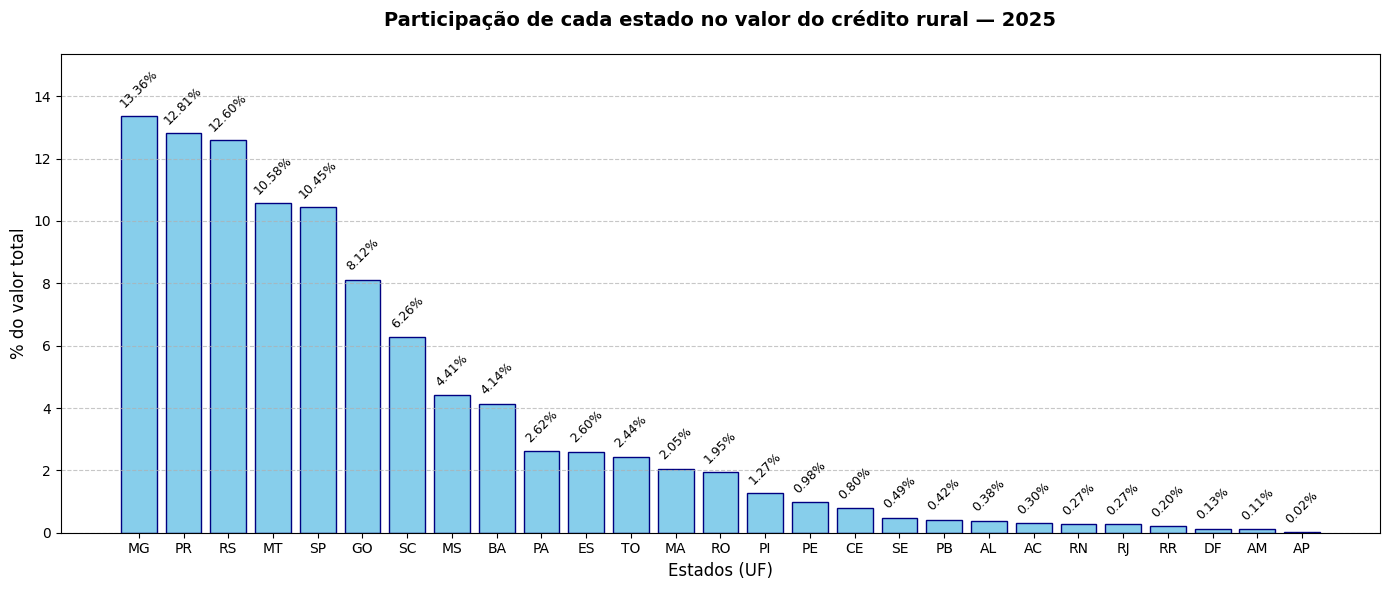

In [48]:
# 1. Ordenando os dados do maior para o menor percentual
dados_ordenados = percentual_uf.sort_values(ascending=False)

# 2. Configurando o tamanho da figura (largura maior para caber todas as UFs)
plt.figure(figsize=(14, 6))

# 3. Criando o gráfico de colunas
barras = plt.bar(
    dados_ordenados.index,      # Siglas no eixo X
    dados_ordenados.values,     # Percentuais no eixo Y
    color='skyblue',            # Cor das colunas
    edgecolor='navy'            # Cor da borda
)

# 4. Adicionando os valores com 2 casas decimais (.2f)
for barra in barras:
    altura = barra.get_height()
    plt.text(
        barra.get_x() + barra.get_width()/2.0, # Posição X
        altura + 0.2,                          # Posição Y
        f'{altura:.2f}%',                      # .2f muda para DUAS casas decimais
        ha='center',
        va='bottom',
        fontsize=9,
        rotation=45                            # Inclina para não trombar
    )

# 5. Customização dos eixos e títulos
plt.title('Participação de cada estado no valor do crédito rural — 2025', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Estados (UF)', fontsize=12)
plt.ylabel('% do valor total', fontsize=12)

# Adiciona linhas de grade horizontais para facilitar a leitura
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Garante que o limite do eixo Y dê espaço para os textos do topo
plt.ylim(0, dados_ordenados.max() * 1.15)

plt.tight_layout()
plt.show()

**📊 Interpretação:**

O gráfico confirma o destaque de **Minas Gerais (13,36%)**, **Paraná (12,81%)** e **Rio Grande do Sul (12,60%)** na participação do valor total. **Amapá (0,02%)** aparece entre os menores percentuais. O gráfico apresenta a distribuição, sem explicar as causas das diferenças estaduais.

### 4.3 — Quantidade de operações por UF

**Procedimento:** Agrupar por estado e contar os números de empréstimo **diferentes** com `nunique()`.

**Objetivo:** A primeira parte da pergunta 1 fala de dinheiro; esta fala de **quantidade**. Um estado pode ter muito dinheiro em poucos empréstimos grandes.

In [49]:
emprestimos_uf = base.groupby("sigla_uf")["id_referencia_bacen"].nunique()

emprestimos_uf = emprestimos_uf.sort_values(ascending=False)

print("Total de empréstimos no Brasil:", base["id_referencia_bacen"].nunique())
print()
print(emprestimos_uf)

Total de empréstimos no Brasil: 1822845

sigla_uf
RS    252097
BA    210905
MG    202799
PR    160314
SC    126511
CE    110440
PE     98592
MA     86892
PI     86802
PB     66821
GO     46948
PA     46506
SP     43852
RN     42809
ES     40994
AL     36331
MT     33111
SE     32165
RO     29103
MS     28219
TO     13914
AC      9850
AM      5938
RJ      4858
AP      3321
RR      2667
DF       380
Name: id_referencia_bacen, dtype: int64


**📊 Interpretação:**

A contagem por `id_referencia_bacen` apresentou **1.822.845 identificadores distintos** no país. Os maiores números foram **Rio Grande do Sul (252.097)**, **Bahia (210.905)** e **Minas Gerais (202.799)**. Essa métrica de identificadores distintos **não deve ser confundida com as 2.442.343 linhas/parcelas** da base.

### 4.4 — Indicadores consolidados por UF

**Procedimento:** Usar `groupby()` com `agg()` para calcular, ao mesmo tempo, a soma do dinheiro e a quantidade de empréstimos. Depois calcular a % e o valor médio por empréstimo (dinheiro ÷ empréstimos).

**Objetivo:** Juntar as duas partes da pergunta 1 numa tabela fácil de comparar. O valor médio por empréstimo mostra se o estado tem empréstimos grandes ou pequenos.

In [50]:
resumo_uf = base.groupby("sigla_uf").agg(
    dinheiro_total=("valor_parcela_credito", "sum"),
    quantidade_emprestimos=("id_referencia_bacen", "nunique")
)

resumo_uf["percentual_dinheiro"] = resumo_uf["dinheiro_total"] / total_brasil * 100
resumo_uf["valor_medio_por_emprestimo"] = resumo_uf["dinheiro_total"] / resumo_uf["quantidade_emprestimos"]

resumo_uf = resumo_uf.sort_values("dinheiro_total", ascending=False)

display(resumo_uf)

,dinheiro_total,quantidade_emprestimos,percentual_dinheiro,valor_medio_por_emprestimo
sigla_uf,,,,
MG,"47,836,038,150.31",202799,13.36,"235,879.06"
PR,"45,879,587,766.37",160314,12.81,"286,185.78"
RS,"45,108,054,276.94",252097,12.60,"178,931.34"
MT,"37,873,507,344.59",33111,10.58,"1,143,834.60"
SP,"37,404,265,651.18",43852,10.45,"852,966.01"
GO,"29,058,009,781.82",46948,8.12,"618,940.31"
SC,"22,427,457,757.94",126511,6.26,"177,276.74"
MS,"15,785,952,121.14",28219,4.41,"559,408.63"
BA,"14,831,182,445.94",210905,4.14,"70,321.63"


**📊 Interpretação:**

Os maiores valores totais foram de **MG (13,36%)**, **PR (12,81%)** e **RS (12,60%)**. Em quantidade de identificadores distintos, lideraram **RS (252.097)**, **BA (210.905)** e **MG (202.799)**. Portanto, **o ranking de dinheiro não coincide com o de quantidade**.

**Resposta da Pergunta 1:** A distribuição territorial do crédito de 2025 foi desigual: Minas Gerais teve a maior participação em valor, enquanto o Rio Grande do Sul liderou a contagem de identificadores distintos de operações.

## Pergunta 2 — O valor muda conforme o tamanho do produtor?

### 4.5 — Indicadores de valores e operações por categoria de produtor

**Procedimento:** Usar `groupby()` com `agg()` para calcular, para cada tipo de produtor: média, **mediana**, quantidade de parcelas e quantidade de empréstimos.

**Objetivo:** A média é puxada pelos valores muito altos (seção 2.7.5). A **mediana** (o valor do meio da fila) mostra melhor a parcela "típica". A quantidade de empréstimos mostra se os grandes produtores têm mesmo menos contratos.

In [51]:
resumo_produtor = base.groupby("tipo_de_produtor").agg(
    media_parcela=("valor_parcela_credito", "mean"),
    mediana_parcela=("valor_parcela_credito", "median"),
    quantidade_parcelas=("valor_parcela_credito", "count"),
    quantidade_emprestimos=("id_referencia_bacen", "nunique")
)

resumo_produtor = resumo_produtor.sort_values("media_parcela", ascending=False)

display(resumo_produtor)

,media_parcela,mediana_parcela,quantidade_parcelas,quantidade_emprestimos
tipo_de_produtor,,,,
Grande Produtor Rural,"1,758,880.35","611,162.36",108351,94376
Médio Produtor Rural,"340,396.34","200,000.00",263257,243471
Pequeno Produtor Rural,"37,612.34","12,000.00",2070735,1484998


**📊 Interpretação:**

A média e a mediana por parcela foram, respectivamente, **R$ 1.758.880,35 e R$ 611.162,36** (grandes), **R$ 340.396,34 e R$ 200.000,00** (médios) e **R$ 37.612,34 e R$ 12.000,00** (pequenos). Em todas as categorias, a média superou a mediana, indicando influência de parcelas elevadas. A tabela registra **94.376**, **243.471** e **1.484.998** identificadores distintos de empréstimos nessas categorias, respectivamente.

### 4.6 — Comparação gráfica das médias por categoria

**Procedimento:** Fazer um gráfico de barras (`plt.bar`) com a média por parcela de cada tipo.

**Objetivo:** O gráfico mostra a diferença de tamanho de forma visual.

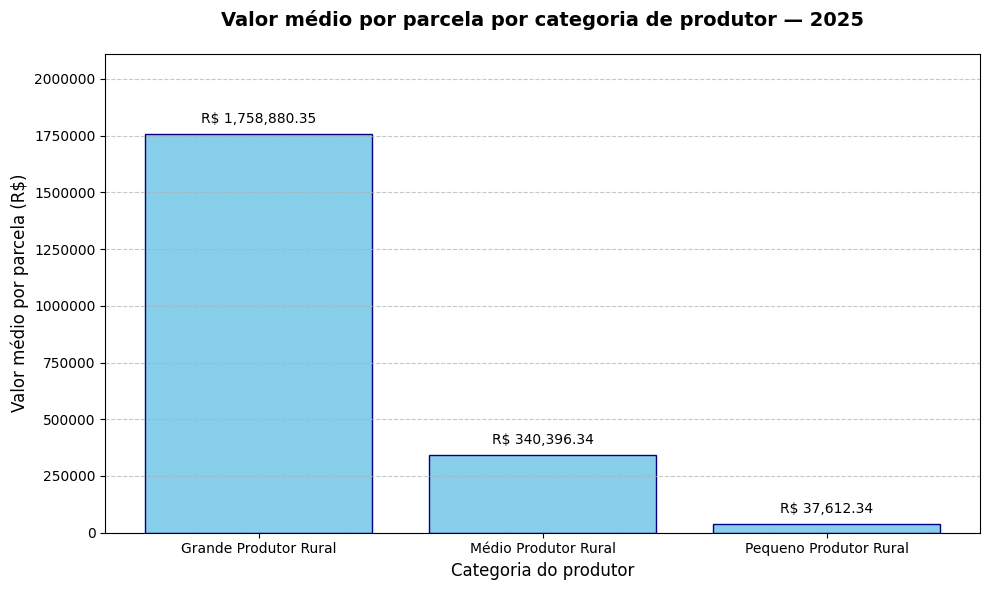

In [52]:
# ==========================================
# PASSO 1: CALCULAR A MÉDIA POR CATEGORIA
# ==========================================
# Agrupa pelos novos nomes de produtores e calcula a média do valor da parcela
df_agrupado = base.groupby('tipo_de_produtor')['valor_parcela_credito'].mean().sort_values(ascending=False)

# Define a variável que o seu código do gráfico espera
media_por_categoria = df_agrupado


# ==========================================
# PASSO 2: CRIAÇÃO DO GRÁFICO (SUA FORMATAÇÃO)
# ==========================================
# 1. Configurando o tamanho da figura
plt.figure(figsize=(10, 6))

# 2. Criando o gráfico de colunas
barras = plt.bar(
    media_por_categoria.index,
    media_por_categoria.values,
    color='skyblue',
    edgecolor='navy'
)

# 3. Adicionando o valor médio acima de cada coluna
for barra in barras:
    altura = barra.get_height()
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        altura + media_por_categoria.max() * 0.02,
        f'R$ {altura:,.2f}',
        ha='center',
        va='bottom',
        fontsize=10
    )

# 4. Customizando os eixos e o título
plt.title('Valor médio por parcela por categoria de produtor — 2025',
          fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Categoria do produtor', fontsize=12)
plt.ylabel('Valor médio por parcela (R$)', fontsize=12)
plt.ticklabel_format(axis='y', style='plain')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.ylim(0, media_por_categoria.max() * 1.20)

plt.tight_layout()
plt.show()

**📊 Interpretação:**

As médias por parcela foram **R$ 1.758.880,35** (grandes), **R$ 340.396,34** (médios) e **R$ 37.612,34** (pequenos). Assim, a média dos grandes foi aproximadamente **46,8 vezes** a dos pequenos. Essa comparação é por **parcela registrada**, não por produtor individual.

### 4.7 — Participação de cada categoria no valor total

**Procedimento:** Somar o dinheiro de cada tipo com `groupby()` + `sum()` e calcular a %.

**Objetivo:** A média mostra o tamanho de cada parcela; a soma mostra quem fica com a maior parte do dinheiro.

In [53]:
total_categoria = base.groupby("tipo_de_produtor")["valor_parcela_credito"].sum().reset_index()
total_categoria = total_categoria.sort_values(by="valor_parcela_credito", ascending=False)

total_geral = total_categoria["valor_parcela_credito"].sum()
percentual_calc = total_categoria["valor_parcela_credito"] / total_geral * 100
total_categoria["percentual_de_participacao"] = percentual_calc.map("{:.2f}%".format)

display(total_categoria)

,tipo_de_produtor,valor_parcela_credito,percentual_de_participacao
0,Grande Produtor Rural,"190,576,444,822.61",53.22%
1,Médio Produtor Rural,"89,611,718,537.91",25.03%
2,Pequeno Produtor Rural,"77,885,187,589.44",21.75%


**📊 Interpretação:**

Os grandes produtores concentraram **53,22%** dos valores (**R$ 190,58 bilhões**), os médios **25,03%** (**R$ 89,61 bilhões**) e os pequenos **21,75%** (**R$ 77,89 bilhões**). Trata-se de participação no valor registrado, não na quantidade de produtores.

### 4.8 — Visualização da participação por categoria

**Procedimento:** Fazer um gráfico de pizza (`plt.pie`) com a divisão do total.

**Objetivo:** A pizza mostra de forma direta quanto cada grupo representa do todo.

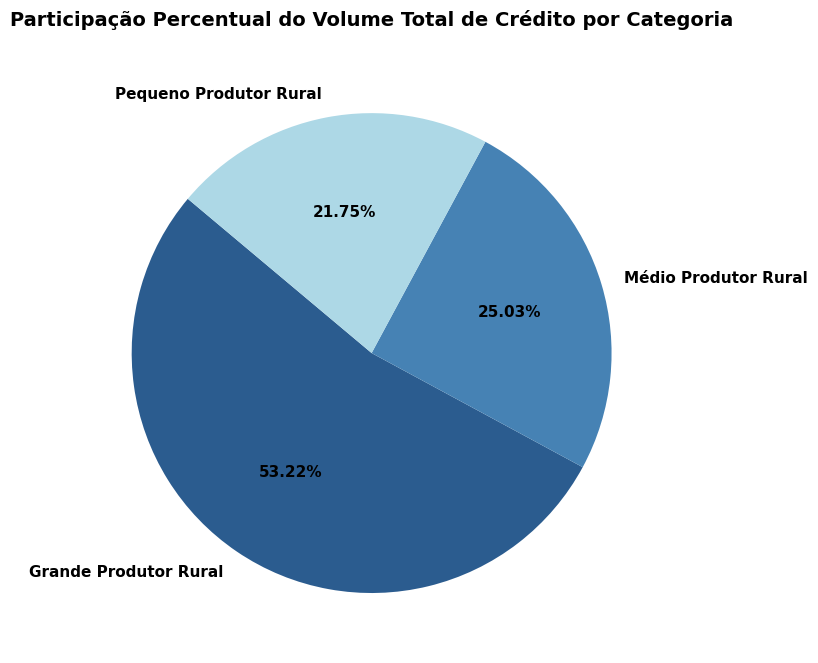

In [54]:
# 1. Configura o tamanho da janela do gráfico
plt.figure(figsize=(8, 8))

# 2. Define uma paleta de cores elegantes para as fatias
cores = ['#2b5c8f', '#4682b4', '#add8e6']

# 3. Cria o gráfico de pizza
plt.pie(
    total_categoria['valor_parcela_credito'],               # Os valores numéricos (soma)
    labels=total_categoria['tipo_de_produtor'].tolist(),    # Os nomes das fatias
    autopct='%1.2f%%',                                      # Formato dos percentuais exibidos (2 casas decimais)
    startangle=140,                                         # Ângulo inicial para melhor posicionamento visual
    colors=cores,                                           # Aplica as cores definidas acima
    textprops={'fontsize': 11, 'fontweight': 'bold'}        # Estilo do texto dentro do gráfico
)

# 4. Adiciona o título do gráfico
plt.title(
    'Participação Percentual do Volume Total de Crédito por Categoria',
    fontsize=14,
    fontweight='bold',
    pad=20
)

# 5. Garante uma exibição limpa
plt.tight_layout()
plt.show()

**📊 Interpretação:**

Os grandes produtores responderam por **53,22% dos valores**, apesar de registrarem **94.376 dos 1.822.845 identificadores distintos** contabilizados na análise nacional (**cerca de 5,18%**, sujeito à consistência da contagem por categoria). Sua média por parcela foi **R$ 1.758.880,35** e a mediana **R$ 611.162,36**.

**Resposta da Pergunta 2:** O grupo de grandes produtores concentrou mais da metade do valor registrado, embora tenha representado uma fração bem menor dos identificadores distintos de operações; a parcela média também foi muito superior à dos demais grupos.

## Pergunta 3 — Para que serve o dinheiro (finalidade)?

### 4.9 — Distribuição do crédito por finalidade

**Procedimento:** Usar `groupby("finalidade")` com `agg()` para calcular soma, média, mediana e quantidade de empréstimos. Depois calcular a % do total.

**Objetivo:** Na seção 2.4 só contamos **tipos de empreendimento** por finalidade. Agora vamos ver o **dinheiro**, que é o que importa.

In [55]:
resumo_finalidade = base.groupby("finalidade").agg(
    dinheiro_total=("valor_parcela_credito", "sum"),
    media_parcela=("valor_parcela_credito", "mean"),
    mediana_parcela=("valor_parcela_credito", "median"),
    quantidade_emprestimos=("id_referencia_bacen", "nunique")
)

resumo_finalidade["percentual_dinheiro"] = resumo_finalidade["dinheiro_total"] / total_brasil * 100

resumo_finalidade = resumo_finalidade.sort_values("dinheiro_total", ascending=False)

display(resumo_finalidade)

,dinheiro_total,media_parcela,mediana_parcela,quantidade_emprestimos,percentual_dinheiro
finalidade,,,,,
Custeio,"191,158,986,549.26","237,327.49","73,000.00",791655,53.39
Investimento,"90,032,993,268.52","55,734.39","8,000.00",1009744,25.14
Comercialização,"48,669,324,760.09","2,462,025.74","436,016.50",19735,13.59
Industrialização,"28,212,046,372.09","16,440,586.46","5,000,000.00",1713,7.88


**📊 Interpretação:**

**Custeio** concentrou o maior valor total (**R$ 191,16 bilhões; 53,39%**), enquanto **Industrialização** apresentou a maior média por parcela (**R$ 16.440.586,46**). Pela contagem de identificadores distintos utilizada na tabela, **Investimento (1.009.744)** superou **Custeio (791.655)**. Assim, o maior volume financeiro não corresponde à maior quantidade de empréstimos.

### 4.10 — Análise do prazo por finalidade

**Procedimento:** Agrupar por finalidade e calcular, com `agg()`, o prazo médio, o prazo mediano e a % de empréstimos de longo prazo (coluna criada na seção 3.6.3).

**Objetivo:** Na seção 3.6.3 dissemos que esperávamos prazos curtos no Custeio (despesas de uma safra) e longos no Investimento (máquinas, estruturas). Aqui conferimos com os números.

In [56]:
base["eh_longo_prazo"] = base["tipo_prazo"] == "Longo prazo"

prazo_finalidade = base.groupby("finalidade").agg(
    prazo_medio_dias=("prazo_dias", "mean"),
    prazo_mediano_dias=("prazo_dias", "median"),
    percentual_longo_prazo=("eh_longo_prazo", "mean")
)

prazo_finalidade["percentual_longo_prazo"] = prazo_finalidade["percentual_longo_prazo"] * 100

display(prazo_finalidade)

,prazo_medio_dias,prazo_mediano_dias,percentual_longo_prazo
finalidade,,,
Comercialização,219.08,180.00,5.41
Custeio,395.61,342.00,28.27
Industrialização,468.26,360.00,25.52
Investimento,"1,524.38","1,096.00",98.69


**📊 Interpretação:**

O prazo mediano foi de **180 dias** na Comercialização, **342 dias** no Custeio, **360 dias** na Industrialização e **1.096 dias** no Investimento. A proporção de registros classificados como longo prazo foi, respectivamente, **5,41%**, **28,27%**, **25,52%** e **98,69%**. O Investimento se destacou pelos prazos mais longos.

### 4.11 — Visualização do valor contratado por finalidade

**Procedimento:** Fazer um gráfico de barras deitadas (`plt.barh`), com o valor em bilhões de reais.

**Objetivo:** Barras deitadas deixam os nomes das finalidades fáceis de ler. Dividir por 1 bilhão evita números com muitos zeros.

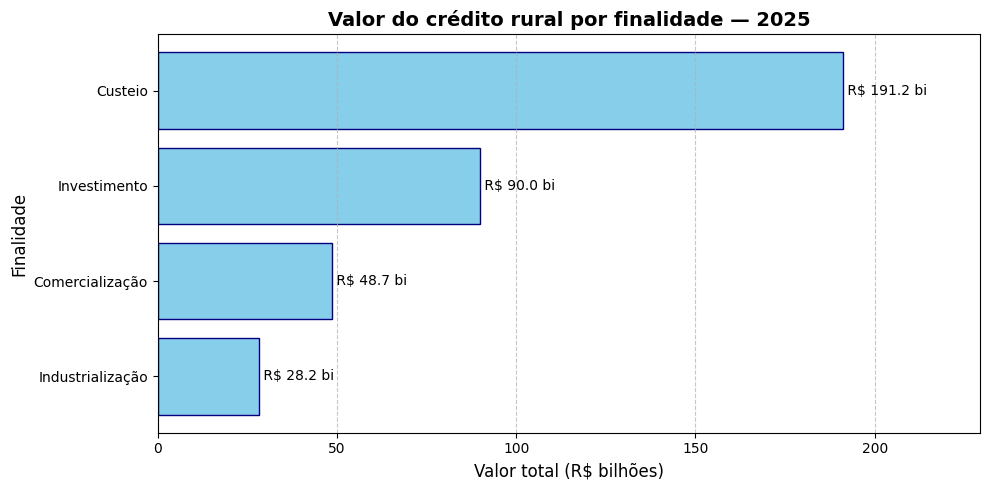

In [57]:
valores_finalidade = resumo_finalidade["dinheiro_total"].sort_values() / 1_000_000_000

plt.figure(figsize=(10, 5))

barras = plt.barh(valores_finalidade.index, valores_finalidade.values, color="skyblue", edgecolor="navy")

for barra in barras:
    largura = barra.get_width()
    plt.text(largura, barra.get_y() + barra.get_height() / 2, f" R$ {largura:,.1f} bi", va="center", fontsize=10)

plt.title("Valor do crédito rural por finalidade — 2025", fontsize=14, fontweight="bold")
plt.xlabel("Valor total (R$ bilhões)", fontsize=12)
plt.ylabel("Finalidade", fontsize=12)
plt.xlim(0, valores_finalidade.max() * 1.2)
plt.grid(axis="x", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

**📊 Interpretação:**

O gráfico mostra que **Custeio** teve a maior participação no valor, com **R$ 191,16 bilhões (53,39%)**. O **Investimento** registrou **25,14%**.

**Resposta da Pergunta 3:** A maior parcela do dinheiro foi destinada ao Custeio, enquanto o Investimento apresentou prazo mediano maior (**1.096 dias**, contra **342 dias** do Custeio).

## Pergunta 4 — Poucos estados e atividades ficam com a maior parte do dinheiro?

### 4.12 — Participação das cinco UFs com maior valor

**Procedimento:** Ordenar os estados do maior para o menor (`sort_values`), pegar os 5 primeiros (`head(5)`) e somar as porcentagens.

**Objetivo:** É a forma mais simples de medir concentração: se 5 dos 27 estados (menos de 1/5) ficam com mais da metade do dinheiro, o crédito está concentrado.

In [58]:
ranking_uf = percentual_uf.sort_values(ascending=False)

top5 = ranking_uf.head(5)
soma_top5 = top5.sum()
soma_outros = 100 - soma_top5

print("Os 5 estados com mais dinheiro:")
print(top5.round(2))
print()
print(f"Os 5 maiores ficam com {soma_top5:.2f}% do dinheiro.")
print(f"Os outros {len(ranking_uf) - 5} estados ficam com {soma_outros:.2f}%.")

Os 5 estados com mais dinheiro:
sigla_uf
MG   13.36
PR   12.81
RS   12.60
MT   10.58
SP   10.45
Name: valor_parcela_credito, dtype: float64

Os 5 maiores ficam com 59.79% do dinheiro.
Os outros 22 estados ficam com 40.21%.


**📊 Interpretação:**

Os cinco estados com maior participação — **MG, PR, RS, MT e SP** — concentraram **59,79%** dos valores, enquanto os outros **22 estados** somaram **40,21%**. Isso indica concentração territorial dos valores registrados.

### 4.13 — Concentração acumulada dos valores por UF

**Procedimento:** Calcular a **porcentagem acumulada** com `cumsum()`: o 1º estado, depois o 1º + o 2º, e assim por diante. Depois contar quantos estados ficam até 50% e até 80%.

**Objetivo:** Mostra a concentração de outro jeito: quanto menos estados forem necessários para chegar a 50%, mais concentrado é o crédito.

In [59]:
acumulado = ranking_uf.cumsum()

tabela_acumulada = pd.DataFrame({
    "percentual": ranking_uf,
    "percentual_acumulado": acumulado
})

display(tabela_acumulada.round(2))

estados_ate_50 = (acumulado < 50).sum() + 1
estados_ate_80 = (acumulado < 80).sum() + 1

print(f"São necessários {estados_ate_50} estados para chegar a 50% do dinheiro.")
print(f"São necessários {estados_ate_80} estados para chegar a 80% do dinheiro.")

,percentual,percentual_acumulado
sigla_uf,,
MG,13.36,13.36
PR,12.81,26.17
RS,12.60,38.77
MT,10.58,49.35
SP,10.45,59.79
GO,8.12,67.91
SC,6.26,74.17
MS,4.41,78.58
BA,4.14,82.72


São necessários 5 estados para chegar a 50% do dinheiro.
São necessários 9 estados para chegar a 80% do dinheiro.


**📊 Interpretação:**

Foram necessários **5 estados** para ultrapassar **50%** do valor total e **9 estados** para ultrapassar **80%**, segundo o acumulado exibido. O conjunto dos cinco principais estados alcançou **59,79%**.

### 4.14 — Comparação entre agricultura e pecuária

**Procedimento:** Usar `groupby("atividade")` com `agg()` para somar o dinheiro e contar os empréstimos, e calcular a %.

**Objetivo:** A pergunta 4 também fala de **atividades**. Precisamos saber se uma delas domina.

In [60]:
resumo_atividade = base.groupby("atividade").agg(
    dinheiro_total=("valor_parcela_credito", "sum"),
    quantidade_emprestimos=("id_referencia_bacen", "nunique")
)

resumo_atividade["percentual_dinheiro"] = resumo_atividade["dinheiro_total"] / total_brasil * 100

display(resumo_atividade)

,dinheiro_total,quantidade_emprestimos,percentual_dinheiro
atividade,,,
Agrícola,"237,981,913,598.28",889110,66.46
Pecuária,"120,091,437,351.68",1134918,33.54


**📊 Interpretação:**

A atividade **Agrícola** respondeu por **66,46%** dos valores (**R$ 237,98 bilhões**), com **889.110 identificadores distintos**. A **Pecuária** representou **33,54%** (**R$ 120,09 bilhões**), com **1.134.918 identificadores distintos**. As contagens de identificadores são diferentes da quantidade de parcelas.

### 4.15 — Concentração dos valores nos dez principais produtos

**Procedimento:** Agrupar por produto, somar o dinheiro, ordenar e pegar os 10 primeiros. Calcular a % de cada um e a % somada dos 10.

**Objetivo:** Existem 316 produtos diferentes (seção 2.4.5). Queremos saber se poucos produtos ficam com a maior parte.

In [61]:
total_produto = base.groupby("produto")["valor_parcela_credito"].sum()

top10_produtos = total_produto.sort_values(ascending=False).head(10)

percentual_top10 = top10_produtos / total_brasil * 100

display(percentual_top10.round(2))

print(f"Os 10 maiores produtos ficam com {percentual_top10.sum():.2f}% do dinheiro.")

produto
BOVINOS                                                                   23.36
SOJA                                                                      19.32
MILHO                                                                      7.89
CAFÉ                                                                       6.15
AQUISIÇÃO DE INSUMOS PARA FORNECIMENTO AOS COOPERADOS                      3.10
CANA-DE-AÇUCAR                                                             2.95
MADEIRA                                                                    2.38
MÁQUINAS E IMPLEMENTOS                                                     2.27
TRATOR                                                                     2.26
ARMAZÉM, DEPÓSITO, SILO, GALPÃO, PAIOL, ESTUFA E INSTALAÇÕES CONGÊNERES    2.18
Name: valor_parcela_credito, dtype: float64

Os 10 maiores produtos ficam com 71.84% do dinheiro.


**📊 Interpretação:**

Os três produtos com maior participação foram **BOVINOS (23,36%)**, **SOJA (19,32%)** e **MILHO (7,89%)**. Os dez produtos principais concentraram **71,84%** dos valores.

**Resposta da Pergunta 4:** Há concentração territorial e por produto: cinco estados responderam por **59,79%** do crédito e os dez produtos mais representativos, por **71,84%**; a atividade Agrícola concentrou **66,46%** do valor.

## Pergunta 5 — O valor muda ao longo dos meses na agricultura e na pecuária?

### 4.16 — Tabela dinâmica do valor mensal por atividade

**Procedimento:** Montar uma tabela com `pd.pivot_table()`: **os meses nas linhas**, **a atividade nas colunas** e **a soma do dinheiro** em cada cruzamento. Os valores são mostrados em bilhões de reais.

**Objetivo:** É exatamente como a **tabela dinâmica do Excel**: cruza duas informações (mês e atividade) numa grade fácil de ler.

In [62]:
tabela_mes = pd.pivot_table(
    base,
    values="valor_parcela_credito",
    index="mes_emissao",
    columns="atividade",
    aggfunc="sum"
)

# Mostrar em bilhões de reais
tabela_mes = tabela_mes / 1_000_000_000

# Trocar o número do mês pelo nome
tabela_mes.index = tabela_mes.index.map(meses)

display(tabela_mes.round(2))

atividade,Agrícola,Pecuária
mes_emissao,,
Jan,10.36,6.66
Fev,14.41,8.26
Mar,16.85,8.48
Abr,19.44,7.63
Mai,24.61,8.99
Jun,26.25,10.77
Jul,18.76,9.54
Ago,28.70,14.22
Set,26.82,14.91


**📊 Interpretação:**

Na **Agrícola**, o maior volume mensal foi em **agosto (R$ 28,70 bilhões)** e o menor em **janeiro (R$ 10,36 bilhões)**. Na **Pecuária**, o maior foi em **setembro (R$ 14,91 bilhões)** e o menor em **janeiro (R$ 6,66 bilhões)**. São totais mensais de valores registrados, sem evidência de sua causa.

### 4.17 — Evolução mensal dos valores por atividade

**Procedimento:** Fazer um gráfico de linha (`plt.plot`) com uma linha para a agricultura e outra para a pecuária.

**Objetivo:** O gráfico de linha mostra bem a **evolução ao longo do tempo**: dá para ver os meses de pico e de queda.

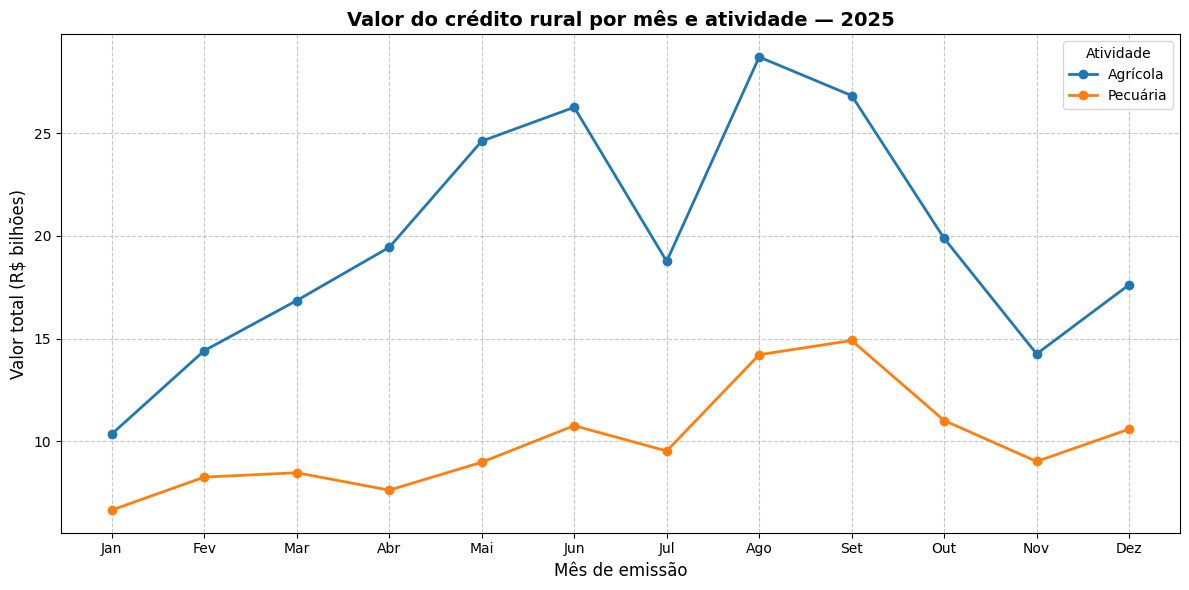

In [63]:
plt.figure(figsize=(12, 6))

for atividade in tabela_mes.columns:
    plt.plot(tabela_mes.index, tabela_mes[atividade], marker="o", linewidth=2, label=atividade)

plt.title("Valor do crédito rural por mês e atividade — 2025", fontsize=14, fontweight="bold")
plt.xlabel("Mês de emissão", fontsize=12)
plt.ylabel("Valor total (R$ bilhões)", fontsize=12)
plt.legend(title="Atividade")
plt.grid(linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

**📊 Interpretação:**

O gráfico evidencia o maior volume da atividade **Agrícola em agosto (R$ 28,70 bilhões)** e da **Pecuária em setembro (R$ 14,91 bilhões)**. Ambas apresentaram os menores valores em **janeiro**. Essas oscilações descrevem **quando** o crédito foi registrado, mas não demonstram suas causas.

**Resposta da Pergunta 5:** O volume financeiro agrícola atingiu seu pico em agosto, enquanto o pecuário atingiu o pico em setembro de 2025.

## Análise complementar com NumPy — Padronização dos valores por UF


### 4.18 — Cálculo do z-score dos valores por UF

**Procedimento:** Calcular o **z-score** de cada estado com NumPy:

1. Pegar o total de dinheiro de cada estado.
2. Calcular a média e o desvio padrão (`np.mean` e `np.std`).
3. Fazer a conta **(valor do estado − média) ÷ desvio padrão** para os 27 estados de uma vez.

**Como ler o z-score:** 0 = estado na média. Positivo = acima da média. Acima de **2** = muito acima do normal.

**Objetivo:** O z-score mostra o quanto cada estado está longe da média, numa régua comum. Reforça a pergunta 4: se poucos estados têm z-score alto, o crédito é concentrado.

**Por que NumPy?** Ele faz a conta nos 27 estados **de uma vez**, sem precisar de repetição (`for`). O código fica mais curto, mais fácil de ler e mais rápido.

In [64]:
# 1. Total de dinheiro de cada estado, como uma lista de números do NumPy
valores = total_uf.to_numpy()

# 2. Média e desvio padrão
media = np.mean(valores)
desvio = np.std(valores)

# 3. Z-score de todos os estados de uma vez
zscore = (valores - media) / desvio

tabela_z = pd.DataFrame({
    "dinheiro_total": valores,
    "zscore": zscore
}, index=total_uf.index)

tabela_z = tabela_z.sort_values("zscore", ascending=False)

display(tabela_z.round(2))

acima_de_2 = (tabela_z["zscore"] > 2).sum()
acima_de_0 = (tabela_z["zscore"] > 0).sum()

print(f"Estados acima da média (z > 0): {acima_de_0} de {len(tabela_z)}")
print(f"Estados muito acima do normal (z > 2): {acima_de_2}")

,dinheiro_total,zscore
sigla_uf,,
MG,"47,836,038,150.31",2.19
PR,"45,879,587,766.37",2.07
RS,"45,108,054,276.94",2.02
MT,"37,873,507,344.59",1.56
SP,"37,404,265,651.18",1.53
GO,"29,058,009,781.82",1.00
SC,"22,427,457,757.94",0.58
MS,"15,785,952,121.14",0.16
BA,"14,831,182,445.94",0.10


Estados acima da média (z > 0): 9 de 27
Estados muito acima do normal (z > 2): 3


**📊 Interpretação:**

O cálculo de z-score mostrou **9 dos 27 estados acima da média** (`z > 0`) e **3 estados com `z > 2`**: **MG (2,19)**, **PR (2,07)** e **RS (2,02)**. Trata-se de uma medida de distância em desvios-padrão da média dos totais estaduais; não comprova inconsistência nem causa da concentração.

## Resumo das respostas

| Pergunta | Resposta em uma frase |
|---|---|
| 1. Estados | MG liderou em valor (**13,36%**), enquanto RS liderou na contagem de identificadores distintos (**252.097**). |
| 2. Tamanho do produtor | Grandes produtores concentraram **53,22%** do valor, com média por parcela de **R$ 1,76 milhão**. |
| 3. Finalidade | **Custeio** concentrou **53,39%** dos valores; **Investimento** teve prazo mediano de **1.096 dias**. |
| 4. Concentração | Os cinco maiores estados concentraram **59,79%** e os dez principais produtos **71,84%** do valor. |
| 5. Meses | O maior total mensal agrícola ocorreu em **agosto** e o pecuário em **setembro**. |

**Nota:** As afirmações acima se baseiam nas saídas salvas no notebook; cálculos e dados devem ser reproduzidos no ambiente final antes da entrega.